#### TowerPulse: 5G Cellular Network Power Consumption Prediction and Energy Efficiency Optimization Using Machine Learning

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import BaggingRegressor,AdaBoostRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from xgboost import XGBRegressor



from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,roc_auc_score
from sklearn.model_selection import train_test_split,GridSearchCV,RandomizedSearchCV

import warnings 
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)


In [2]:
df=pd.read_csv('Dataset_02_NR_2100.txt')

In [3]:
df

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL
0,Site 61,1,2/27/2025 7:30,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35
1,Site 61,2,2/27/2025 7:30,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98
2,Site 61,3,2/27/2025 7:30,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73
3,Site 61,1,2/24/2025 1:15,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,NaN,NaN,0.00
4,Site 61,2,2/24/2025 1:15,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,Site 244,2,4/9/2025 18:30,26.0,84.0,1.0,1.0,10.49,1.43,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94
1048571,Site 244,1,4/21/2025 17:45,38.0,89.0,2.0,1.0,123.08,10.10,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99
1048572,Site 244,2,4/21/2025 17:45,27.0,89.0,1.0,1.0,25.97,3.65,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49
1048573,Site 244,1,4/7/2025 9:00,36.0,82.0,2.0,2.0,57.56,5.58,9.0,2.82,9.26,9.37,10.07,5.50,5.19,1.01,1.02,2.10


##### Creating a function to check the outliers for all the numerical columns 

In [4]:
def check_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f"\nColumn: {column}")
    print(f"Q1: {Q1}")
    print(f"Q3: {Q3}")
    print(f"IQR: {IQR}")
    print(f"Lower Limit: {lower_limit}")
    print(f"Upper Limit: {upper_limit}")
    print(f"Number of Outliers: {len(outliers)}")

    return outliers

##### creating a function for Numerical EDA 

In [5]:
def numerical_eda(df, column):

    data = df[column].dropna()

    print("=" * 50)
    print(f"Numerical EDA: {column}")
    print("=" * 50)

    # Basic information
    print(f"Data Type       : {df[column].dtype}")
    print(f"Null Count      : {df[column].isnull().sum()}")
    print(f"Null Percentage : {df[column].isnull().mean() * 100:.2f}%")
    print(f"Unique Values   : {df[column].nunique()}")

    # Statistics
    print("\n--- Statistics ---")
    print(f"Mean            : {data.mean():.2f}")
    print(f"Median          : {data.median():.2f}")
    print(f"Std Dev         : {data.std():.2f}")
    print(f"Minimum         : {data.min():.2f}")
    print(f"Maximum         : {data.max():.2f}")

    # Percentiles
    print("\n--- Percentiles ---")
    print(f"25%             : {data.quantile(0.25):.2f}")
    print(f"50%             : {data.quantile(0.50):.2f}")
    print(f"75%             : {data.quantile(0.75):.2f}")

    # Skewness
    print("\n--- Distribution ---")
    print(f"Skewness        : {data.skew():.3f}")

    # Histogram
    plt.figure(figsize=(8, 4))
    sns.histplot(data, kde=True)
    plt.title(f"Distribution - {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

    # KDE
    plt.figure(figsize=(8, 4))
    sns.kdeplot(data, fill=True)
    plt.title(f"KDE Plot - {column}")
    plt.xlabel(column)
    plt.ylabel("Density")
    plt.show()

    # Box plot
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=data)
    plt.title(f"Box Plot - {column}")
    plt.xlabel(column)
    plt.show()

In [6]:
cols=df.columns
cols

Index(['Base station', 'Sector', 'Timestamp', 'Radio unit energy consumption',
       'Baseband energy consumption', '5G max active users DL',
       '5G max active users UL', '5G data volume DL', '5G data volume UL',
       '5G max RRC users', '5G RB utilization', '5G CQI rank 1',
       '5G CQI rank 2', '5G CQI rank 3', '5G CQI rank 4', '5G RRC users',
       '5G active users UL', '5G active users DL', '5G MIMO rank DL'],
      dtype='str')

In [7]:
df.shape

(1048575, 19)

In [8]:
df.isna().sum()

Base station                          0
Sector                                0
Timestamp                             0
Radio unit energy consumption     70472
Baseband energy consumption       70423
5G max active users DL           681475
5G max active users UL           681475
5G data volume DL                681475
5G data volume UL                681475
5G max RRC users                 681475
5G RB utilization                681475
5G CQI rank 1                    681587
5G CQI rank 2                    681587
5G CQI rank 3                    681587
5G CQI rank 4                    681587
5G RRC users                     681475
5G active users UL               696575
5G active users DL               694506
5G MIMO rank DL                  681587
dtype: int64

#### Base Station 

In [9]:
df["Base station"].unique()

<StringArray>
[ 'Site 61', 'Site 188',  'Site 96',  'Site 82', 'Site 236', 'Site 205',
 'Site 190', 'Site 265',   'Site 7', 'Site 119', 'Site 200', 'Site 197',
 'Site 279',   'Site 5',  'Site 90', 'Site 107',  'Site 22', 'Site 254',
  'Site 16',  'Site 53', 'Site 225',   'Site 4',   'Site 6',  'Site 29',
 'Site 141', 'Site 161', 'Site 111', 'Site 222', 'Site 133', 'Site 178',
 'Site 215',  'Site 40', 'Site 201', 'Site 136', 'Site 103', 'Site 245',
 'Site 228', 'Site 194', 'Site 144',  'Site 34', 'Site 143', 'Site 202',
 'Site 230',  'Site 45',  'Site 88', 'Site 171', 'Site 130', 'Site 125',
  'Site 69', 'Site 227', 'Site 244']
Length: 51, dtype: str

In [10]:
df['Base station'].value_counts()

Base station
Site 5      47744
Site 279    44448
Site 61     44439
Site 82     44424
Site 205    44421
Site 200    44415
Site 197    44406
Site 53     42328
Site 188    41758
Site 254    41416
Site 96     41396
Site 22     35826
Site 236    35814
Site 190    35814
Site 90     35808
Site 119    35157
Site 107    33272
Site 7      32806
Site 265    32786
Site 225    27210
Site 16     27186
Site 141     8616
Site 201     8616
Site 228     8616
Site 144     8616
Site 69      8616
Site 4       8610
Site 6       8610
Site 29      8610
Site 161     8610
Site 222     8610
Site 133     8610
Site 178     8610
Site 215     8610
Site 136     8610
Site 103     8610
Site 194     8610
Site 34      8610
Site 202     8610
Site 230     8610
Site 88      8610
Site 130     8610
Site 45      8607
Site 40      8598
Site 125     8592
Site 171     5744
Site 111     5740
Site 143     5740
Site 227     5740
Site 245     5728
Site 244      372
Name: count, dtype: int64

#### Sector

In [11]:
df["Sector"].unique()

array([1, 2, 3, 4, 5])

In [12]:
df["Sector"].value_counts()

Sector
1    352851
2    352851
3    315819
4     21006
5      6048
Name: count, dtype: int64

In [13]:
df[(df['Sector']==1) & (df['Baseband energy consumption']>60)]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL
0,Site 61,1,2/27/2025 7:30,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35
3,Site 61,1,2/24/2025 1:15,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,NaN,NaN,0.00
6,Site 61,1,2/26/2025 19:45,38.0,89.0,1.0,1.0,0.06,0.01,1.0,2.50,8.97,6.07,0.00,0.00,0.01,1.00,1.00,1.29
9,Site 61,1,2/11/2025 3:45,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,NaN,NaN,0.00
12,Site 61,1,3/6/2025 12:45,42.0,89.0,1.0,1.0,23.12,2.97,4.0,2.70,11.20,7.60,6.57,8.50,1.02,1.01,1.01,1.66
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048565,Site 244,1,4/21/2025 17:00,37.0,89.0,1.0,1.0,328.45,14.59,8.0,4.32,10.79,11.37,9.90,6.45,4.00,1.02,1.06,2.08
1048567,Site 244,1,4/9/2025 3:15,26.0,82.0,1.0,1.0,0.25,0.01,1.0,2.50,15.00,14.21,10.90,0.00,0.18,1.00,1.00,2.03
1048569,Site 244,1,4/9/2025 18:30,40.0,84.0,1.0,1.0,207.92,38.49,7.0,3.03,12.41,12.58,10.88,9.43,4.21,1.02,1.03,1.96
1048571,Site 244,1,4/21/2025 17:45,38.0,89.0,2.0,1.0,123.08,10.10,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99


#### TimeStamp

In [14]:
df["Timestamp"].unique()

<StringArray>
[ '2/27/2025 7:30',  '2/24/2025 1:15', '2/26/2025 19:45',  '2/11/2025 3:45',
  '3/6/2025 12:45',  '2/28/2025 6:45', '2/10/2025 18:45', '2/22/2025 23:00',
  '3/1/2025 20:15',  '3/9/2025 13:30',
 ...
  '5/3/2025 14:45',   '4/7/2025 2:30',  '4/7/2025 19:15',   '5/5/2025 5:00',
  '4/11/2025 2:45', '4/10/2025 12:00',  '4/25/2025 0:30',  '4/26/2025 6:15',
   '5/5/2025 7:15', '4/18/2025 14:45']
Length: 5898, dtype: str

In [15]:
df[(df['Timestamp']=='2/24/2025 1:15') & (df['Sector']==1) & (df['Base station']=='Site 61')]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL
3,Site 61,1,2/24/2025 1:15,22.0,89.0,0.0,0.0,0.0,0.0,0.0,2.5,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0
115110,Site 61,1,2/24/2025 1:15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368523,Site 61,1,2/24/2025 1:15,0.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
df[(df['Timestamp']=='2/27/2025 7:30') & (df['Sector']==1) & (df['Base station']=='Site 244')]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL


In [17]:
df[(df['Timestamp']=='2/27/2025 7:30') & (df['Base station']=='Site 188	')]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL


In [18]:
df[df['Base station']=='Site 188'].isna().sum()

Base station                         0
Sector                               0
Timestamp                            0
Radio unit energy consumption       16
Baseband energy consumption          0
5G max active users DL           24073
5G max active users UL           24073
5G data volume DL                24073
5G data volume UL                24073
5G max RRC users                 24073
5G RB utilization                24073
5G CQI rank 1                    24079
5G CQI rank 2                    24079
5G CQI rank 3                    24079
5G CQI rank 4                    24079
5G RRC users                     24073
5G active users UL               24180
5G active users DL               24146
5G MIMO rank DL                  24079
dtype: int64

In [19]:
df['Timestamp'].unique()

<StringArray>
[ '2/27/2025 7:30',  '2/24/2025 1:15', '2/26/2025 19:45',  '2/11/2025 3:45',
  '3/6/2025 12:45',  '2/28/2025 6:45', '2/10/2025 18:45', '2/22/2025 23:00',
  '3/1/2025 20:15',  '3/9/2025 13:30',
 ...
  '5/3/2025 14:45',   '4/7/2025 2:30',  '4/7/2025 19:15',   '5/5/2025 5:00',
  '4/11/2025 2:45', '4/10/2025 12:00',  '4/25/2025 0:30',  '4/26/2025 6:15',
   '5/5/2025 7:15', '4/18/2025 14:45']
Length: 5898, dtype: str

In [20]:
timestamp = '2/27/2025 7:30'
sites=df['Base station'].unique()


# Filter rows for the given timestamp
df_time = df[df['Timestamp'].astype(str) == timestamp]

# Check which sites are present
present_sites = df_time['Base station'].unique()

# Find missing and available sites
available = [site for site in sites if site in present_sites]
missing = [site for site in sites if site not in present_sites]

print("Total sites checked:", len(sites))
print("Sites present:", len(available))
print("Sites missing:", len(missing))

print("\nPresent sites:", available)
print("\nMissing sites:", missing)

print("\nTimestamp exists for all sites:", len(missing) == 0)

Total sites checked: 51
Sites present: 21
Sites missing: 30

Present sites: ['Site 61', 'Site 188', 'Site 96', 'Site 82', 'Site 236', 'Site 205', 'Site 190', 'Site 265', 'Site 7', 'Site 119', 'Site 200', 'Site 197', 'Site 279', 'Site 5', 'Site 90', 'Site 107', 'Site 22', 'Site 254', 'Site 16', 'Site 53', 'Site 225']

Missing sites: ['Site 4', 'Site 6', 'Site 29', 'Site 141', 'Site 161', 'Site 111', 'Site 222', 'Site 133', 'Site 178', 'Site 215', 'Site 40', 'Site 201', 'Site 136', 'Site 103', 'Site 245', 'Site 228', 'Site 194', 'Site 144', 'Site 34', 'Site 143', 'Site 202', 'Site 230', 'Site 45', 'Site 88', 'Site 171', 'Site 130', 'Site 125', 'Site 69', 'Site 227', 'Site 244']

Timestamp exists for all sites: False


In [21]:
import pandas as pd

# Convert Timestamp to datetime
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')

# Create separate date and time columns
df['Date'] = df['Timestamp'].dt.date
df['Day'] = df['Timestamp'].dt.day
df['Month'] = df['Timestamp'].dt.month
df['Year'] = df['Timestamp'].dt.year

# Time-related columns
df['Hour'] = df['Timestamp'].dt.hour
df['Minute'] = df['Timestamp'].dt.minute
df['Time'] = df['Timestamp'].dt.strftime('%H:%M')

# Day of week: Monday = 0, Sunday = 6
df['Day_of_Week'] = df['Timestamp'].dt.dayofweek

# 15-minute time slot: 00:00, 00:15, 00:30, 00:45, etc.
df['Time_Slot'] = (
    df['Timestamp'].dt.hour * 4
    + df['Timestamp'].dt.minute // 15
)

df.head()

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot
0,Site 61,1,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.0,0.53,1.0,1.0,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30
1,Site 61,2,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.5,1.37,1.0,1.0,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30
2,Site 61,3,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.0,0.43,1.0,1.0,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30
3,Site 61,1,2025-02-24 01:15:00,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.0,0.00,NaN,NaN,0.00,2025-02-24,24,2,2025,1,15,01:15,0,5
4,Site 61,2,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.0,1.15,1.0,1.0,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5


In [22]:
df['Month'].min()

np.int32(2)

#### So data set from feb to May 

In [23]:
df['Day'].min()

np.int32(1)

In [24]:
df[(df['Month']==2)]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot
0,Site 61,1,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30
1,Site 61,2,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30
2,Site 61,3,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30
3,Site 61,1,2025-02-24 01:15:00,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,NaN,NaN,0.00,2025-02-24,24,2,2025,1,15,01:15,0,5
4,Site 61,2,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
575121,Site 16,2,2025-02-10 20:45:00,81.0,89.0,2.0,2.0,373.56,15.88,7.0,8.67,6.78,6.09,3.42,2.94,4.14,1.22,1.11,1.63,2025-02-10,10,2,2025,20,45,20:45,0,83
575122,Site 16,3,2025-02-10 20:45:00,41.0,89.0,1.0,1.0,0.04,0.03,1.0,2.50,7.39,5.25,0.00,0.00,0.04,1.00,1.00,1.10,2025-02-10,10,2,2025,20,45,20:45,0,83
575123,Site 16,1,2025-02-19 18:00:00,65.0,88.0,2.0,1.0,304.06,8.08,9.0,5.27,6.51,7.77,10.50,3.70,3.65,1.03,1.06,1.99,2025-02-19,19,2,2025,18,0,18:00,2,72
575124,Site 16,2,2025-02-19 18:00:00,70.0,88.0,2.0,2.0,160.87,8.98,8.0,8.88,6.33,5.89,9.52,7.12,2.57,1.15,1.12,1.27,2025-02-19,19,2,2025,18,0,18:00,2,72


In [25]:
df[(df['Month']==2) & (df['Day']==7) & (df['Hour']==19) & (df['Minute']==45)]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot
2895,Site 61,1,2025-02-07 19:45:00,38.0,89.0,1.0,1.0,15.78,0.35,1.0,2.84,4.68,5.79,1.75,1.00,0.16,1.00,1.00,1.92,2025-02-07,7,2,2025,19,45,19:45,4,79
2896,Site 61,2,2025-02-07 19:45:00,36.0,89.0,2.0,1.0,194.13,3.45,6.0,3.53,9.02,10.79,3.00,1.82,3.21,1.02,1.02,1.90,2025-02-07,7,2,2025,19,45,19:45,4,79
2897,Site 61,3,2025-02-07 19:45:00,31.0,89.0,1.0,1.0,13.52,0.59,1.0,2.58,11.10,10.00,0.00,0.00,0.20,1.00,1.00,1.88,2025-02-07,7,2,2025,19,45,19:45,4,79
26412,Site 82,1,2025-02-07 19:45:00,62.0,87.0,2.0,2.0,300.98,19.11,12.0,5.96,9.27,8.03,7.97,7.16,5.89,1.07,1.08,1.79,2025-02-07,7,2,2025,19,45,19:45,4,79
26413,Site 82,2,2025-02-07 19:45:00,56.0,87.0,1.0,1.0,39.83,5.82,6.0,2.68,11.98,8.79,9.41,5.08,2.94,1.01,1.01,1.67,2025-02-07,7,2,2025,19,45,19:45,4,79
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
537230,Site 225,2,2025-02-07 19:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-07,7,2,2025,19,45,19:45,4,79
537231,Site 225,3,2025-02-07 19:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-07,7,2,2025,19,45,19:45,4,79
558743,Site 225,1,2025-02-07 19:45:00,56.0,99.0,2.0,2.0,1306.05,22.59,7.0,11.98,10.10,10.55,7.56,5.44,4.15,1.07,1.08,1.82,2025-02-07,7,2,2025,19,45,19:45,4,79
558744,Site 225,2,2025-02-07 19:45:00,64.0,99.0,2.0,2.0,815.66,25.55,10.0,16.91,9.37,7.19,7.32,4.10,6.06,1.13,1.17,1.62,2025-02-07,7,2,2025,19,45,19:45,4,79


#### So data set from feb to May  , And Staring Date is 7-feb-2025 Time 19:45

In [26]:
df[(df['Month']==5) & (df['Day']==5) & (df['Hour']==7) & (df['Minute']==15)]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot
624542,Site 96,1,2025-05-05 07:15:00,64.0,88.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,7,15,07:15,0,29
624543,Site 96,2,2025-05-05 07:15:00,63.0,88.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,7,15,07:15,0,29
624544,Site 96,3,2025-05-05 07:15:00,65.0,88.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,7,15,07:15,0,29
660200,Site 141,1,2025-05-05 07:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,7,15,07:15,0,29
660201,Site 141,2,2025-05-05 07:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,7,15,07:15,0,29
660202,Site 141,3,2025-05-05 07:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,7,15,07:15,0,29
698157,Site 82,1,2025-05-05 07:15:00,85.0,84.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,7,15,07:15,0,29
698158,Site 82,2,2025-05-05 07:15:00,85.0,84.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,7,15,07:15,0,29
698159,Site 82,3,2025-05-05 07:15:00,90.0,84.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,7,15,07:15,0,29
731949,Site 265,1,2025-05-05 07:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,7,15,07:15,0,29


In [27]:
cols

Index(['Base station', 'Sector', 'Timestamp', 'Radio unit energy consumption',
       'Baseband energy consumption', '5G max active users DL',
       '5G max active users UL', '5G data volume DL', '5G data volume UL',
       '5G max RRC users', '5G RB utilization', '5G CQI rank 1',
       '5G CQI rank 2', '5G CQI rank 3', '5G CQI rank 4', '5G RRC users',
       '5G active users UL', '5G active users DL', '5G MIMO rank DL'],
      dtype='str')

#### Radio unit energy consumption

In [28]:
df['Radio unit energy consumption'].isna().sum()

np.int64(70472)

In [29]:
df.isna().sum()

Base station                          0
Sector                                0
Timestamp                             0
Radio unit energy consumption     70472
Baseband energy consumption       70423
5G max active users DL           681475
5G max active users UL           681475
5G data volume DL                681475
5G data volume UL                681475
5G max RRC users                 681475
5G RB utilization                681475
5G CQI rank 1                    681587
5G CQI rank 2                    681587
5G CQI rank 3                    681587
5G CQI rank 4                    681587
5G RRC users                     681475
5G active users UL               696575
5G active users DL               694506
5G MIMO rank DL                  681587
Date                                  0
Day                                   0
Month                                 0
Year                                  0
Hour                                  0
Minute                                0


In [30]:
df

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot
0,Site 61,1,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30
1,Site 61,2,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30
2,Site 61,3,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30
3,Site 61,1,2025-02-24 01:15:00,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,NaN,NaN,0.00,2025-02-24,24,2,2025,1,15,01:15,0,5
4,Site 61,2,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,Site 244,2,2025-04-09 18:30:00,26.0,84.0,1.0,1.0,10.49,1.43,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94,2025-04-09,9,4,2025,18,30,18:30,2,74
1048571,Site 244,1,2025-04-21 17:45:00,38.0,89.0,2.0,1.0,123.08,10.10,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99,2025-04-21,21,4,2025,17,45,17:45,0,71
1048572,Site 244,2,2025-04-21 17:45:00,27.0,89.0,1.0,1.0,25.97,3.65,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49,2025-04-21,21,4,2025,17,45,17:45,0,71
1048573,Site 244,1,2025-04-07 09:00:00,36.0,82.0,2.0,2.0,57.56,5.58,9.0,2.82,9.26,9.37,10.07,5.50,5.19,1.01,1.02,2.10,2025-04-07,7,4,2025,9,0,09:00,0,36


In [31]:
df[df['Radio unit energy consumption']==0]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot
30573,Site 236,1,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41
30574,Site 236,2,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41
30575,Site 236,3,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41
30576,Site 236,1,2025-02-17 01:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-17,17,2,2025,1,30,01:30,0,6
30577,Site 236,2,2025-02-17 01:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-17,17,2,2025,1,30,01:30,0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048198,Site 227,2,2025-04-29 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-29,29,4,2025,10,15,10:15,1,41
1048199,Site 227,1,2025-04-30 22:45:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-30,30,4,2025,22,45,22:45,2,91
1048200,Site 227,2,2025-04-30 22:45:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-30,30,4,2025,22,45,22:45,2,91
1048201,Site 227,1,2025-04-21 23:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-21,21,4,2025,23,30,23:30,0,94


In [32]:
df[df['Baseband energy consumption']==0]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot


In [33]:
energy_cols = [
    'Radio unit energy consumption',
    'Baseband energy consumption'
]

for col in energy_cols:
    print(f"\n{col}")
    print("Missing values:", df[col].isna().sum())
    print("Zero values:", (df[col] == 0).sum())
    print("Positive values:", (df[col] > 0).sum())
    print("Negative values:", (df[col] < 0).sum())
    print(df[col].describe())


Radio unit energy consumption
Missing values: 70472
Zero values: 397584
Positive values: 580519
Negative values: 0
count    978103.000000
mean         38.237485
std          35.928802
min           0.000000
25%           0.000000
50%          42.000000
75%          67.000000
max         162.000000
Name: Radio unit energy consumption, dtype: float64

Baseband energy consumption
Missing values: 70423
Zero values: 0
Positive values: 978152
Negative values: 0
count    978152.000000
mean         59.545417
std          33.215308
min          18.000000
25%          20.000000
50%          83.000000
75%          88.000000
max         102.000000
Name: Baseband energy consumption, dtype: float64


In [34]:
print(
    "Both zero:",
    ((df[energy_cols[0]] == 0) &
     (df[energy_cols[1]] == 0)).sum()
)

print(
    "RU zero, BBU positive:",
    ((df[energy_cols[0]] == 0) &
     (df[energy_cols[1]] > 0)).sum()
)

print(
    "BBU zero, RU positive:",
    ((df[energy_cols[1]] == 0) &
     (df[energy_cols[0]] > 0)).sum()
)

Both zero: 0
RU zero, BBU positive: 397584
BBU zero, RU positive: 0


In [35]:
ru = 'Radio unit energy consumption'
bbu = 'Baseband energy consumption'

print("Both missing:",
      (df[ru].isna() & df[bbu].isna()).sum())

print("RU missing, BBU available:",
      (df[ru].isna() & df[bbu].notna()).sum())

print("BBU missing, RU available:",
      (df[bbu].isna() & df[ru].notna()).sum())

Both missing: 70423
RU missing, BBU available: 49
BBU missing, RU available: 0


### drop the adio unit energy consumption boz have 397584 0 power values 

In [36]:
df['Radio unit energy consumption']

0          39.0
1          34.0
2          32.0
3          22.0
4          22.0
           ... 
1048570    26.0
1048571    38.0
1048572    27.0
1048573    36.0
1048574    26.0
Name: Radio unit energy consumption, Length: 1048575, dtype: float64

In [37]:
cols

Index(['Base station', 'Sector', 'Timestamp', 'Radio unit energy consumption',
       'Baseband energy consumption', '5G max active users DL',
       '5G max active users UL', '5G data volume DL', '5G data volume UL',
       '5G max RRC users', '5G RB utilization', '5G CQI rank 1',
       '5G CQI rank 2', '5G CQI rank 3', '5G CQI rank 4', '5G RRC users',
       '5G active users UL', '5G active users DL', '5G MIMO rank DL'],
      dtype='str')

### Baseband energy consumption

In [38]:
df['Baseband energy consumption'].isna().sum()

np.int64(70423)

In [39]:
df[df['Baseband energy consumption']<20]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot
30591,Site 236,1,2025-02-18 00:45:00,0.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-18,18,2,2025,0,45,00:45,1,3
30592,Site 236,2,2025-02-18 00:45:00,0.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-18,18,2,2025,0,45,00:45,1,3
30593,Site 236,3,2025-02-18 00:45:00,0.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-18,18,2,2025,0,45,00:45,1,3
30672,Site 236,1,2025-02-19 03:30:00,0.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-19,19,2,2025,3,30,03:30,2,14
30673,Site 236,2,2025-02-19 03:30:00,0.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-19,19,2,2025,3,30,03:30,2,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016640,Site 130,2,2025-04-10 12:00:00,0.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-10,10,4,2025,12,0,12:00,3,48
1016641,Site 130,3,2025-04-10 12:00:00,0.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-10,10,4,2025,12,0,12:00,3,48
1016642,Site 130,1,2025-05-05 05:00:00,0.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,5,0,05:00,0,20
1016643,Site 130,2,2025-05-05 05:00:00,0.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-05,5,5,2025,5,0,05:00,0,20


#### All 5G  coloumns 

In [40]:
cols_5g = [
    '5G max active users DL',
    '5G max active users UL',
    '5G data volume DL',
    '5G data volume UL',
    '5G max RRC users',
    '5G RB utilization',
    '5G CQI rank 1',
    '5G CQI rank 2',
    '5G CQI rank 3',
    '5G CQI rank 4',
    '5G RRC users',
    '5G active users UL',
    '5G active users DL',
    '5G MIMO rank DL'
]

for col in cols_5g:
    print(f"\n{col}:")
    print(df.index[df[col].isnull()].tolist())


5G max active users DL:


IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [41]:
null_index_5g_features=df.index[df[cols_5g].isnull().all(axis=1)].tolist()

In [42]:
#null_index_5g_features

In [43]:
import warnings
warnings.filterwarnings('ignore')

In [44]:
df.isna().sum()

Base station                          0
Sector                                0
Timestamp                             0
Radio unit energy consumption     70472
Baseband energy consumption       70423
5G max active users DL           681475
5G max active users UL           681475
5G data volume DL                681475
5G data volume UL                681475
5G max RRC users                 681475
5G RB utilization                681475
5G CQI rank 1                    681587
5G CQI rank 2                    681587
5G CQI rank 3                    681587
5G CQI rank 4                    681587
5G RRC users                     681475
5G active users UL               696575
5G active users DL               694506
5G MIMO rank DL                  681587
Date                                  0
Day                                   0
Month                                 0
Year                                  0
Hour                                  0
Minute                                0


Numerical EDA: Baseband energy consumption
Data Type       : float64
Null Count      : 70423
Null Percentage : 6.72%
Unique Values   : 49

--- Statistics ---
Mean            : 59.55
Median          : 83.00
Std Dev         : 33.22
Minimum         : 18.00
Maximum         : 102.00

--- Percentiles ---
25%             : 20.00
50%             : 83.00
75%             : 88.00

--- Distribution ---
Skewness        : -0.299


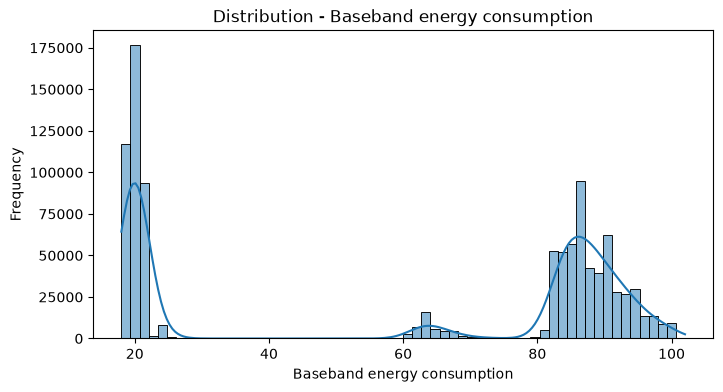

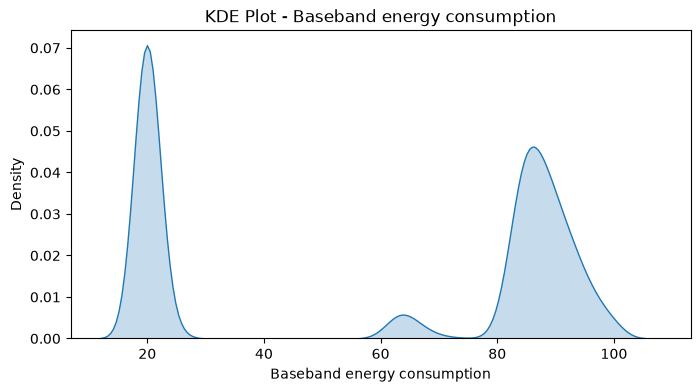

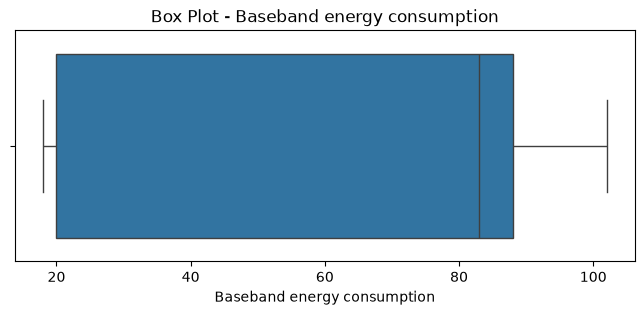

In [45]:
numerical_eda(df,'Baseband energy consumption')

#### Filling Null values 

In [46]:
df['Baseband energy consumption'].mean()

np.float64(59.54541727666048)

In [47]:
df['Baseband energy consumption'].fillna(59)

0          89.0
1          89.0
2          89.0
3          89.0
4          89.0
           ... 
1048570    84.0
1048571    89.0
1048572    89.0
1048573    82.0
1048574    82.0
Name: Baseband energy consumption, Length: 1048575, dtype: float64

In [48]:
cols

Index(['Base station', 'Sector', 'Timestamp', 'Radio unit energy consumption',
       'Baseband energy consumption', '5G max active users DL',
       '5G max active users UL', '5G data volume DL', '5G data volume UL',
       '5G max RRC users', '5G RB utilization', '5G CQI rank 1',
       '5G CQI rank 2', '5G CQI rank 3', '5G CQI rank 4', '5G RRC users',
       '5G active users UL', '5G active users DL', '5G MIMO rank DL'],
      dtype='str')

#### 5G max active users DL

In [49]:
df['5G max active users DL'].isna().sum()

np.int64(681475)

In [50]:
df[(df['5G max active users DL'].isna()) & (df['Baseband energy consumption'].between(0,30))]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot
30573,Site 236,1,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41
30574,Site 236,2,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41
30575,Site 236,3,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41
30576,Site 236,1,2025-02-17 01:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-17,17,2,2025,1,30,01:30,0,6
30577,Site 236,2,2025-02-17 01:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-17,17,2,2025,1,30,01:30,0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048198,Site 227,2,2025-04-29 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-29,29,4,2025,10,15,10:15,1,41
1048199,Site 227,1,2025-04-30 22:45:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-30,30,4,2025,22,45,22:45,2,91
1048200,Site 227,2,2025-04-30 22:45:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-30,30,4,2025,22,45,22:45,2,91
1048201,Site 227,1,2025-04-21 23:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-21,21,4,2025,23,30,23:30,0,94


### From this the Baseband energy consumption start from 62 for non null values of 5G features

In [51]:
df[(df['5G max active users DL'].notna()) & (df['Baseband energy consumption'].between(0,62))]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot
903917,Site 200,1,2025-04-06 02:00:00,49.0,62.0,1.0,1.0,0.17,0.02,1.0,2.50,0.00,11.47,8.97,0.00,0.04,1.0,1.0,2.57,2025-04-06,6,4,2025,2,0,02:00,6,8
903918,Site 200,2,2025-04-06 02:00:00,44.0,62.0,0.0,0.0,0.00,0.00,1.0,2.50,8.00,6.19,5.00,0.00,0.01,NaN,NaN,2.00,2025-04-06,6,4,2025,2,0,02:00,6,8
903919,Site 200,3,2025-04-06 02:00:00,37.0,62.0,1.0,1.0,2.44,0.19,2.0,2.51,9.55,10.62,8.59,0.00,0.16,1.0,1.0,2.14,2025-04-06,6,4,2025,2,0,02:00,6,8
903947,Site 200,1,2025-04-08 00:00:00,39.0,62.0,1.0,1.0,9.65,0.57,1.0,2.62,9.23,5.70,8.72,0.00,0.18,1.0,1.0,1.82,2025-04-08,8,4,2025,0,0,00:00,1,0
903948,Site 200,2,2025-04-08 00:00:00,47.0,62.0,1.0,1.0,20.62,1.63,1.0,2.58,11.19,9.74,10.72,9.58,0.23,1.0,1.0,2.22,2025-04-08,8,4,2025,0,0,00:00,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
912366,Site 200,2,2025-04-07 02:00:00,44.0,62.0,1.0,1.0,0.07,0.01,1.0,2.50,0.00,8.77,10.61,0.00,0.04,1.0,1.0,2.27,2025-04-07,7,4,2025,2,0,02:00,0,8
912367,Site 200,3,2025-04-07 02:00:00,37.0,62.0,1.0,1.0,2.43,0.11,1.0,2.50,12.67,10.93,10.60,0.00,0.02,1.0,1.0,2.75,2025-04-07,7,4,2025,2,0,02:00,0,8
912389,Site 200,1,2025-04-06 21:15:00,47.0,62.0,1.0,1.0,42.92,1.41,1.0,2.71,11.86,8.77,6.79,3.77,0.27,1.0,1.0,1.69,2025-04-06,6,4,2025,21,15,21:15,6,85
912390,Site 200,2,2025-04-06 21:15:00,50.0,62.0,1.0,1.0,3.99,0.48,1.0,2.51,8.69,11.37,9.39,5.80,0.14,1.0,1.0,2.42,2025-04-06,6,4,2025,21,15,21:15,6,85


In [53]:
df[(df['5G max active users DL'].isna()) & (df['Baseband energy consumption'].between(0,62))]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot
30573,Site 236,1,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41
30574,Site 236,2,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41
30575,Site 236,3,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41
30576,Site 236,1,2025-02-17 01:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-17,17,2,2025,1,30,01:30,0,6
30577,Site 236,2,2025-02-17 01:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-17,17,2,2025,1,30,01:30,0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048198,Site 227,2,2025-04-29 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-29,29,4,2025,10,15,10:15,1,41
1048199,Site 227,1,2025-04-30 22:45:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-30,30,4,2025,22,45,22:45,2,91
1048200,Site 227,2,2025-04-30 22:45:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-30,30,4,2025,22,45,22:45,2,91
1048201,Site 227,1,2025-04-21 23:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-21,21,4,2025,23,30,23:30,0,94


In [54]:
col = '5G max active users DL'
power = 'Baseband energy consumption'

df['Power_Group'] = pd.cut(
    df[power],
    bins=[-float('inf'), 62, float('inf')],
    labels=['Below or equal to 62', 'Above 62']
)

result = df.groupby('Power_Group', observed=False)[col].agg(
    Total_Rows='size',
    Non_Null='count'
)

result['Null'] = result['Total_Rows'] - result['Non_Null']

print(result)

                      Total_Rows  Non_Null    Null
Power_Group                                       
Below or equal to 62      406674       399  406275
Above 62                  571478    366701  204777


In [55]:
df.loc[
    (df[power].between(0, 62)) &
    (df[col].isna()),
    [power, col]
].shape

(406275, 2)

In [56]:
df.loc[
    (df[power] > 62) &
    (df[col].isna()),
    [power, col]
].shape

(204777, 2)

In [57]:
df.shape

(1048575, 29)

In [58]:
df[(df['5G max active users DL'].notna()) & (df['Baseband energy consumption']>100)]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group
308703,Site 7,1,2025-02-11 16:45:00,53.0,101.0,1.0,1.0,204.79,6.58,4.0,5.06,6.06,6.73,11.06,8.62,1.38,1.01,1.02,2.07,2025-02-11,11,2,2025,16,45,16:45,1,67,Above 62
308704,Site 7,2,2025-02-11 16:45:00,56.0,101.0,1.0,1.0,269.94,71.47,3.0,3.91,10.77,11.77,9.45,5.59,0.63,1.00,1.00,2.09,2025-02-11,11,2,2025,16,45,16:45,1,67,Above 62
308705,Site 7,3,2025-02-11 16:45:00,72.0,101.0,1.0,1.0,713.15,16.73,5.0,6.57,11.14,11.56,10.81,10.18,2.34,1.01,1.03,2.22,2025-02-11,11,2,2025,16,45,16:45,1,67,Above 62
308814,Site 7,1,2025-02-10 15:30:00,60.0,101.0,1.0,1.0,243.79,12.06,6.0,5.11,10.23,7.39,5.85,3.77,2.88,1.02,1.04,1.77,2025-02-10,10,2,2025,15,30,15:30,0,62,Above 62
308815,Site 7,2,2025-02-10 15:30:00,57.0,101.0,2.0,1.0,135.11,3.80,4.0,3.36,11.15,9.67,9.44,8.44,2.01,1.00,1.01,1.99,2025-02-10,10,2,2025,15,30,15:30,0,62,Above 62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317641,Site 7,2,2025-02-27 09:30:00,66.0,101.0,2.0,2.0,285.30,11.22,6.0,4.53,10.68,9.59,10.12,6.43,2.73,1.02,1.04,2.02,2025-02-27,27,2,2025,9,30,09:30,3,38,Above 62
317642,Site 7,3,2025-02-27 09:30:00,70.0,101.0,2.0,2.0,372.25,24.43,7.0,4.02,9.84,10.98,10.86,9.12,3.66,1.02,1.03,1.99,2025-02-27,27,2,2025,9,30,09:30,3,38,Above 62
317739,Site 7,1,2025-02-26 22:30:00,51.0,101.0,1.0,1.0,151.95,10.54,4.0,4.38,6.73,9.28,9.48,6.50,2.48,1.07,1.05,1.98,2025-02-26,26,2,2025,22,30,22:30,2,90,Above 62
317740,Site 7,2,2025-02-26 22:30:00,60.0,101.0,1.0,1.0,296.35,11.30,3.0,7.59,9.57,7.44,5.33,2.67,1.88,1.07,1.05,1.50,2025-02-26,26,2,2025,22,30,22:30,2,90,Above 62


In [59]:
df.loc[
    (df['Baseband energy consumption'] > 100) &
    (df['5G max active users DL'].notna()),
    '5G max active users DL'
].max()

np.float64(2.0)

In [60]:
df[(df['5G max active users DL'].isna()) & (df['Baseband energy consumption'].between(0,62))]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group
30573,Site 236,1,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41,Below or equal to 62
30574,Site 236,2,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41,Below or equal to 62
30575,Site 236,3,2025-03-01 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-01,1,3,2025,10,15,10:15,5,41,Below or equal to 62
30576,Site 236,1,2025-02-17 01:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-17,17,2,2025,1,30,01:30,0,6,Below or equal to 62
30577,Site 236,2,2025-02-17 01:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-17,17,2,2025,1,30,01:30,0,6,Below or equal to 62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048198,Site 227,2,2025-04-29 10:15:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-29,29,4,2025,10,15,10:15,1,41,Below or equal to 62
1048199,Site 227,1,2025-04-30 22:45:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-30,30,4,2025,22,45,22:45,2,91,Below or equal to 62
1048200,Site 227,2,2025-04-30 22:45:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-30,30,4,2025,22,45,22:45,2,91,Below or equal to 62
1048201,Site 227,1,2025-04-21 23:30:00,0.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-21,21,4,2025,23,30,23:30,0,94,Below or equal to 62


In [61]:
df.isna().sum()

Base station                          0
Sector                                0
Timestamp                             0
Radio unit energy consumption     70472
Baseband energy consumption       70423
5G max active users DL           681475
5G max active users UL           681475
5G data volume DL                681475
5G data volume UL                681475
5G max RRC users                 681475
5G RB utilization                681475
5G CQI rank 1                    681587
5G CQI rank 2                    681587
5G CQI rank 3                    681587
5G CQI rank 4                    681587
5G RRC users                     681475
5G active users UL               696575
5G active users DL               694506
5G MIMO rank DL                  681587
Date                                  0
Day                                   0
Month                                 0
Year                                  0
Hour                                  0
Minute                                0


In [62]:
list_null_g5_power_b_0_61=df.index[(df['5G max active users DL'].isna()) & (df['Baseband energy consumption'].between(0,62))].tolist()

In [63]:
len(list_null_g5_power_b_0_61)

406275

In [ ]:
"""
Lets create a new DataFrame by dropping the 406,275 rows where `5G max active
users DL` is null and `Baseband energy consumption` is between 0 and 62. Keep the remaining rows,
where the 5G values are non-null or the power consumption is above 62.
"""

In [64]:
df2=df.drop(list_null_g5_power_b_0_61,axis=0)

In [65]:
df2.max()

Base station                                 Site 96
Sector                                             5
Timestamp                        2025-05-05 07:15:00
Radio unit energy consumption                  162.0
Baseband energy consumption                    102.0
5G max active users DL                          22.0
5G max active users UL                          18.0
5G data volume DL                           20256.34
5G data volume UL                            6791.76
5G max RRC users                                76.0
5G RB utilization                              92.46
5G CQI rank 1                                   15.0
5G CQI rank 2                                   15.0
5G CQI rank 3                                   15.0
5G CQI rank 4                                   15.0
5G RRC users                                   51.12
5G active users UL                              8.46
5G active users DL                              9.32
5G MIMO rank DL                               

In [66]:
df2[(df2['5G max active users DL'].notna()) & (df2['Baseband energy consumption'].between(62,71))]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group
184703,Site 200,1,2025-02-15 07:45:00,40.0,63.0,1.0,1.0,30.99,3.00,2.0,2.71,13.45,9.50,7.75,11.80,0.63,1.00,1.00,1.62,2025-02-15,15,2,2025,7,45,07:45,5,31,Above 62
184704,Site 200,2,2025-02-15 07:45:00,46.0,63.0,1.0,1.0,4.00,0.39,2.0,2.52,9.54,10.30,9.84,10.40,0.18,1.00,1.00,1.98,2025-02-15,15,2,2025,7,45,07:45,5,31,Above 62
184705,Site 200,3,2025-02-15 07:45:00,38.0,63.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,10.56,0.00,0.00,NaN,NaN,3.00,2025-02-15,15,2,2025,7,45,07:45,5,31,Above 62
184706,Site 200,1,2025-02-23 13:15:00,43.0,65.0,1.0,1.0,186.53,5.39,3.0,3.80,10.12,8.08,5.05,3.34,0.96,1.04,1.07,2.03,2025-02-23,23,2,2025,13,15,13:15,6,53,Above 62
184707,Site 200,2,2025-02-23 13:15:00,61.0,65.0,1.0,1.0,63.37,2.43,2.0,2.69,11.48,13.20,10.87,7.64,1.20,1.00,1.02,2.12,2025-02-23,23,2,2025,13,15,13:15,6,53,Above 62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
912450,Site 200,2,2025-04-17 00:00:00,47.0,66.0,1.0,1.0,1.05,0.09,2.0,2.50,12.75,10.70,9.60,0.00,0.06,1.00,1.00,2.10,2025-04-17,17,4,2025,0,0,00:00,3,0,Above 62
912451,Site 200,3,2025-04-17 00:00:00,41.0,66.0,1.0,1.0,175.84,3.54,2.0,3.02,11.03,11.45,11.68,9.63,1.11,1.00,1.01,2.83,2025-04-17,17,4,2025,0,0,00:00,3,0,Above 62
912458,Site 200,1,2025-04-22 09:15:00,38.0,70.0,1.0,1.0,4.63,0.30,1.0,2.57,14.62,9.24,11.93,0.00,0.23,1.00,1.00,1.95,2025-04-22,22,4,2025,9,15,09:15,1,37,Above 62
912459,Site 200,2,2025-04-22 09:15:00,49.0,70.0,1.0,1.0,28.55,1.37,4.0,2.76,10.54,8.96,10.74,9.52,0.68,1.00,1.00,1.96,2025-04-22,22,4,2025,9,15,09:15,1,37,Above 62


In [67]:
df2[(df2['5G max active users DL'].isna()) & (df2['Baseband energy consumption'].between(62,71))]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group
127309,Site 200,1,2025-02-23 17:30:00,68.0,63.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-23,23,2,2025,17,30,17:30,6,70,Above 62
127310,Site 200,2,2025-02-23 17:30:00,94.0,63.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-23,23,2,2025,17,30,17:30,6,70,Above 62
127311,Site 200,3,2025-02-23 17:30:00,71.0,63.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-23,23,2,2025,17,30,17:30,6,70,Above 62
127318,Site 200,1,2025-03-03 12:00:00,68.0,63.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-03,3,3,2025,12,0,12:00,0,48,Above 62
127319,Site 200,2,2025-03-03 12:00:00,62.0,63.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-03-03,3,3,2025,12,0,12:00,0,48,Above 62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
809130,Site 200,2,2025-04-21 10:30:00,64.0,66.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-21,21,4,2025,10,30,10:30,0,42,Above 62
809131,Site 200,3,2025-04-21 10:30:00,66.0,66.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-21,21,4,2025,10,30,10:30,0,42,Above 62
809132,Site 200,1,2025-04-29 23:15:00,68.0,63.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-29,29,4,2025,23,15,23:15,1,93,Above 62
809133,Site 200,2,2025-04-29 23:15:00,63.0,63.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-29,29,4,2025,23,15,23:15,1,93,Above 62


In [68]:
power = 'Baseband energy consumption'

# Select rows where power is between 62 and 70
mask = df2[power].between(62, 70)

# Select the 5G columns
cols_5g = [
    '5G max active users DL',
    '5G max active users UL',
    '5G data volume DL',
    '5G data volume UL',
    '5G max RRC users',
    '5G RB utilization',
    '5G CQI rank 1',
    '5G CQI rank 2',
    '5G CQI rank 3',
    '5G CQI rank 4',
    '5G RRC users',
    '5G active users UL',
    '5G active users DL',
    '5G MIMO rank DL'
]

# Calculate the median of each 5G column in this range
medians = df2.loc[mask, cols_5g].median()

print(medians)

5G max active users DL     1.00
5G max active users UL     1.00
5G data volume DL         29.87
5G data volume UL          1.68
5G max RRC users           2.00
5G RB utilization          2.63
5G CQI rank 1             10.38
5G CQI rank 2              9.67
5G CQI rank 3              9.52
5G CQI rank 4              7.74
5G RRC users               0.64
5G active users UL         1.00
5G active users DL         1.00
5G MIMO rank DL            2.03
dtype: float64


In [69]:
power = 'Baseband energy consumption'

# Define power ranges
ranges = [
    (62, 70),
    (70, 80),
    (80, 90),
    (90, 102)
]

# Fill missing values range by range
for lower, upper in ranges:

    mask = (
        df2[power].ge(lower) &
        (df2[power].le(upper) if upper == 102
         else df2[power].lt(upper))
    )

    # Calculate median for each 5G column in this range
    medians = df2.loc[mask, cols_5g].median()

    # Fill missing values directly in df2
    for col in cols_5g:
        missing_mask = mask & df2[col].isna()
        df2.loc[missing_mask, col] = medians[col]

    print(f"Completed power range: {lower}-{upper}")

Completed power range: 62-70
Completed power range: 70-80
Completed power range: 80-90
Completed power range: 90-102


In [70]:
df2.isna().sum()

Base station                         0
Sector                               0
Timestamp                            0
Radio unit energy consumption    70472
Baseband energy consumption      70423
5G max active users DL           70423
5G max active users UL           70423
5G data volume DL                70423
5G data volume UL                70423
5G max RRC users                 70423
5G RB utilization                70423
5G CQI rank 1                    70423
5G CQI rank 2                    70423
5G CQI rank 3                    70423
5G CQI rank 4                    70423
5G RRC users                     70423
5G active users UL               70423
5G active users DL               70423
5G MIMO rank DL                  70423
Date                                 0
Day                                  0
Month                                0
Year                                 0
Hour                                 0
Minute                               0
Time                     

In [71]:
df2[df2['Baseband energy consumption'].isna()]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group
112194,Site 61,1,2025-02-27 03:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-27,27,2,2025,3,15,03:15,3,13,NaN
112195,Site 61,2,2025-02-27 03:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-27,27,2,2025,3,15,03:15,3,13,NaN
112196,Site 61,3,2025-02-27 03:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-27,27,2,2025,3,15,03:15,3,13,NaN
112197,Site 61,1,2025-02-24 05:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-24,24,2,2025,5,30,05:30,0,22,NaN
112198,Site 61,2,2025-02-24 05:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-02-24,24,2,2025,5,30,05:30,0,22,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
959239,Site 202,2,2025-04-13 19:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-13,13,4,2025,19,15,19:15,6,77,NaN
959240,Site 202,3,2025-04-13 19:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-13,13,4,2025,19,15,19:15,6,77,NaN
959241,Site 202,1,2025-04-10 04:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-10,10,4,2025,4,15,04:15,3,17,NaN
959242,Site 202,2,2025-04-10 04:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-04-10,10,4,2025,4,15,04:15,3,17,NaN


In [72]:
list_of_power_null=df2.index[df2['Baseband energy consumption'].isna()].tolist()

In [74]:
#list_of_power_null

In [75]:
df2=df2.drop(list_of_power_null,axis=0)

In [76]:
df2.isna().sum()

Base station                      0
Sector                            0
Timestamp                         0
Radio unit energy consumption    49
Baseband energy consumption       0
5G max active users DL            0
5G max active users UL            0
5G data volume DL                 0
5G data volume UL                 0
5G max RRC users                  0
5G RB utilization                 0
5G CQI rank 1                     0
5G CQI rank 2                     0
5G CQI rank 3                     0
5G CQI rank 4                     0
5G RRC users                      0
5G active users UL                0
5G active users DL                0
5G MIMO rank DL                   0
Date                              0
Day                               0
Month                             0
Year                              0
Hour                              0
Minute                            0
Time                              0
Day_of_Week                       0
Time_Slot                   

Numerical EDA: Radio unit energy consumption
Data Type       : float64
Null Count      : 49
Null Percentage : 0.01%
Unique Values   : 149

--- Statistics ---
Mean            : 64.40
Median          : 63.00
Std Dev         : 22.25
Minimum         : 14.00
Maximum         : 162.00

--- Percentiles ---
25%             : 46.00
50%             : 63.00
75%             : 86.00

--- Distribution ---
Skewness        : 0.082


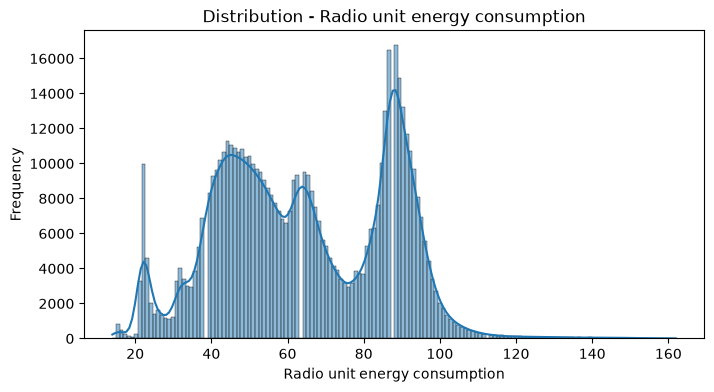

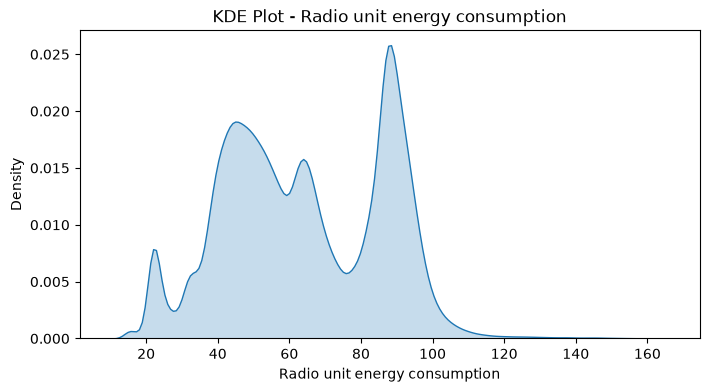

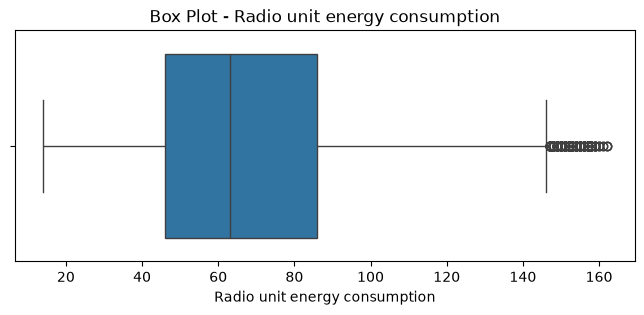

In [77]:
numerical_eda(df2,'Radio unit energy consumption')

In [78]:
df2['Radio unit energy consumption']=df2['Radio unit energy consumption'].fillna(63.00,inplace=True)

In [79]:
df2.isna().sum()

Base station                     0
Sector                           0
Timestamp                        0
Radio unit energy consumption    0
Baseband energy consumption      0
5G max active users DL           0
5G max active users UL           0
5G data volume DL                0
5G data volume UL                0
5G max RRC users                 0
5G RB utilization                0
5G CQI rank 1                    0
5G CQI rank 2                    0
5G CQI rank 3                    0
5G CQI rank 4                    0
5G RRC users                     0
5G active users UL               0
5G active users DL               0
5G MIMO rank DL                  0
Date                             0
Day                              0
Month                            0
Year                             0
Hour                             0
Minute                           0
Time                             0
Day_of_Week                      0
Time_Slot                        0
Power_Group         

Numerical EDA: Radio unit energy consumption
Data Type       : float64
Null Count      : 0
Null Percentage : 0.00%
Unique Values   : 149

--- Statistics ---
Mean            : 64.40
Median          : 63.00
Std Dev         : 22.25
Minimum         : 14.00
Maximum         : 162.00

--- Percentiles ---
25%             : 46.00
50%             : 63.00
75%             : 86.00

--- Distribution ---
Skewness        : 0.082


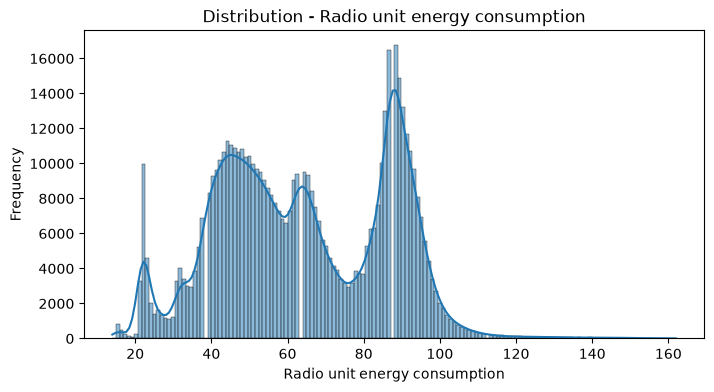

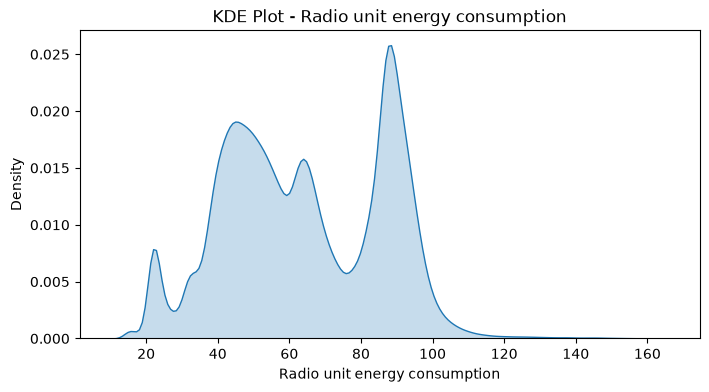

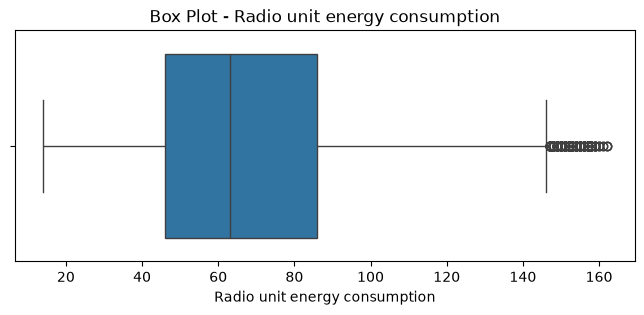

In [80]:
numerical_eda(df2,'Radio unit energy consumption')

Numerical EDA: Baseband energy consumption
Data Type       : float64
Null Count      : 0
Null Percentage : 0.00%
Unique Values   : 38

--- Statistics ---
Mean            : 86.97
Median          : 87.00
Std Dev         : 7.04
Minimum         : 62.00
Maximum         : 102.00

--- Percentiles ---
25%             : 84.00
50%             : 87.00
75%             : 91.00

--- Distribution ---
Skewness        : -1.479


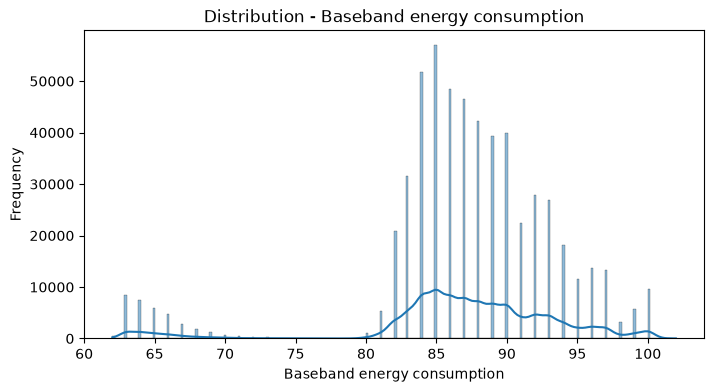

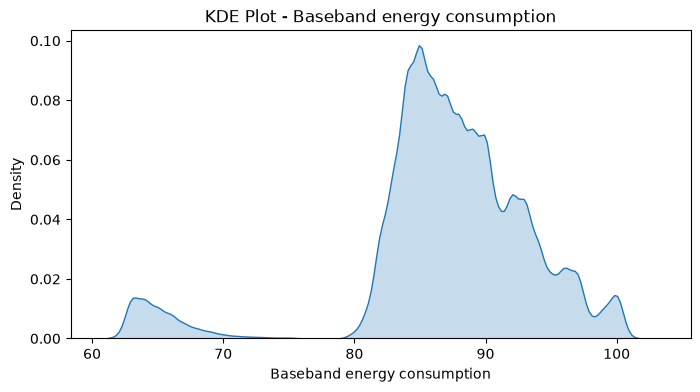

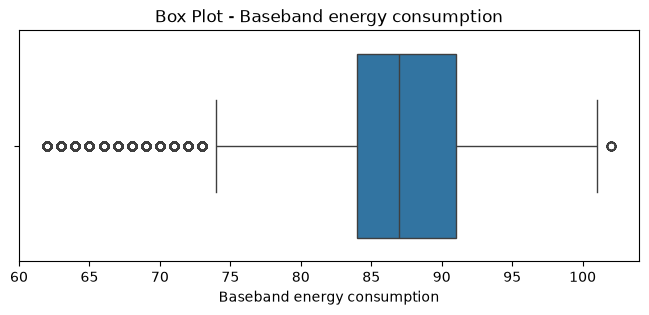

In [81]:
numerical_eda(df2,'Baseband energy consumption')

In [82]:
cols

Index(['Base station', 'Sector', 'Timestamp', 'Radio unit energy consumption',
       'Baseband energy consumption', '5G max active users DL',
       '5G max active users UL', '5G data volume DL', '5G data volume UL',
       '5G max RRC users', '5G RB utilization', '5G CQI rank 1',
       '5G CQI rank 2', '5G CQI rank 3', '5G CQI rank 4', '5G RRC users',
       '5G active users UL', '5G active users DL', '5G MIMO rank DL'],
      dtype='str')

In [83]:
df2.shape

(571877, 29)

#### 5G max active users DL

In [85]:
df2['5G max active users DL']

0          1.0
1          1.0
2          1.0
3          0.0
4          1.0
          ... 
1048570    1.0
1048571    2.0
1048572    1.0
1048573    2.0
1048574    1.0
Name: 5G max active users DL, Length: 571877, dtype: float64

Numerical EDA: 5G max active users DL
Data Type       : float64
Null Count      : 0
Null Percentage : 0.00%
Unique Values   : 20

--- Statistics ---
Mean            : 1.25
Median          : 1.00
Std Dev         : 0.65
Minimum         : 0.00
Maximum         : 22.00

--- Percentiles ---
25%             : 1.00
50%             : 1.00
75%             : 1.00

--- Distribution ---
Skewness        : 4.676


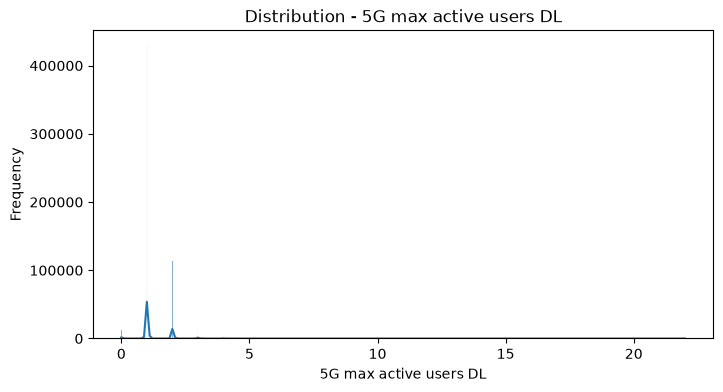

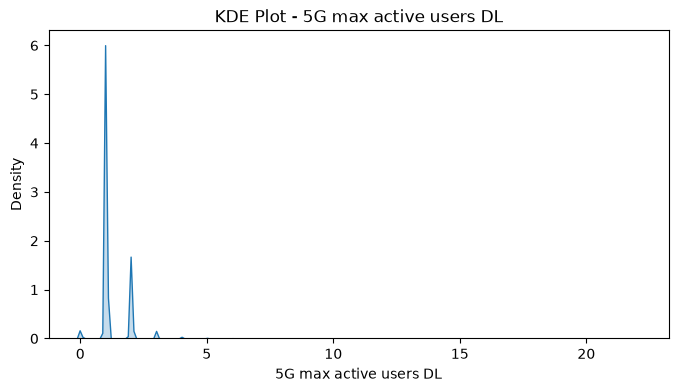

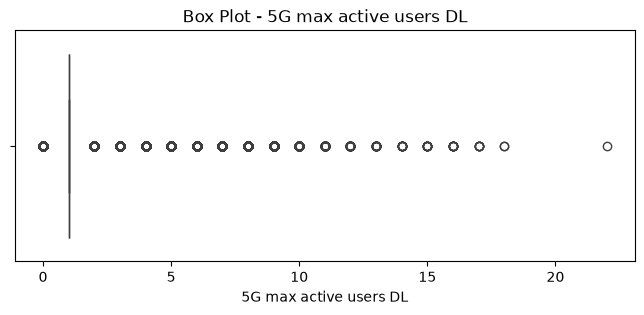

In [86]:
numerical_eda(df2,'5G max active users DL')

In [87]:
df2[df2['5G max active users DL']==1]

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group
0,Site 61,1,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62
1,Site 61,2,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62
2,Site 61,3,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62
4,Site 61,2,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62
6,Site 61,1,2025-02-26 19:45:00,38.0,89.0,1.0,1.0,0.06,0.01,1.0,2.50,8.97,6.07,0.00,0.00,0.01,1.00,1.00,1.29,2025-02-26,26,2,2025,19,45,19:45,2,79,Above 62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048567,Site 244,1,2025-04-09 03:15:00,26.0,82.0,1.0,1.0,0.25,0.01,1.0,2.50,15.00,14.21,10.90,0.00,0.18,1.00,1.00,2.03,2025-04-09,9,4,2025,3,15,03:15,2,13,Above 62
1048569,Site 244,1,2025-04-09 18:30:00,40.0,84.0,1.0,1.0,207.92,38.49,7.0,3.03,12.41,12.58,10.88,9.43,4.21,1.02,1.03,1.96,2025-04-09,9,4,2025,18,30,18:30,2,74,Above 62
1048570,Site 244,2,2025-04-09 18:30:00,26.0,84.0,1.0,1.0,10.49,1.43,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94,2025-04-09,9,4,2025,18,30,18:30,2,74,Above 62
1048572,Site 244,2,2025-04-21 17:45:00,27.0,89.0,1.0,1.0,25.97,3.65,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62


In [88]:
df2.columns

Index(['Base station', 'Sector', 'Timestamp', 'Radio unit energy consumption',
       'Baseband energy consumption', '5G max active users DL',
       '5G max active users UL', '5G data volume DL', '5G data volume UL',
       '5G max RRC users', '5G RB utilization', '5G CQI rank 1',
       '5G CQI rank 2', '5G CQI rank 3', '5G CQI rank 4', '5G RRC users',
       '5G active users UL', '5G active users DL', '5G MIMO rank DL', 'Date',
       'Day', 'Month', 'Year', 'Hour', 'Minute', 'Time', 'Day_of_Week',
       'Time_Slot', 'Power_Group'],
      dtype='str')

In [89]:
# Each row represents a 15-minute interval
interval_seconds = 15 * 60

df2['DL_Throughput_Mbps'] = (
    df2['5G data volume DL'] * 8 / interval_seconds
)

df2['UL_Throughput_Mbps'] = (
    df2['5G data volume UL'] * 8 / interval_seconds
)

In [90]:
df2[
    [
        '5G data volume DL',
        '5G data volume UL',
        'Baseband energy consumption'
    ]
].describe()

,5G data volume DL,5G data volume UL,Baseband energy consumption
count,571877.000000,571877.000000,571877.000000
mean,283.071422,17.401270,86.972216
std,496.424879,52.116284,7.036115
min,0.000000,0.000000,62.000000
25%,73.420000,3.690000,84.000000
50%,122.950000,5.810000,87.000000
75%,237.290000,11.530000,91.000000
max,20256.340000,6791.760000,102.000000


In [91]:
df2

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group,DL_Throughput_Mbps,UL_Throughput_Mbps
0,Site 61,1,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.153422,0.017600
1,Site 61,2,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.238844,0.009778
2,Site 61,3,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.323467,0.015467
3,Site 61,1,2025-02-24 01:15:00,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,1.01,1.02,0.00,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000000,0.000000
4,Site 61,2,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000711,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,Site 244,2,2025-04-09 18:30:00,26.0,84.0,1.0,1.0,10.49,1.43,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94,2025-04-09,9,4,2025,18,30,18:30,2,74,Above 62,0.093244,0.012711
1048571,Site 244,1,2025-04-21 17:45:00,38.0,89.0,2.0,1.0,123.08,10.10,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,1.094044,0.089778
1048572,Site 244,2,2025-04-21 17:45:00,27.0,89.0,1.0,1.0,25.97,3.65,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,0.230844,0.032444
1048573,Site 244,1,2025-04-07 09:00:00,36.0,82.0,2.0,2.0,57.56,5.58,9.0,2.82,9.26,9.37,10.07,5.50,5.19,1.01,1.02,2.10,2025-04-07,7,4,2025,9,0,09:00,0,36,Above 62,0.511644,0.049600


In [92]:
df2['5G RB utilization'].unique()

array([ 2.94,  2.61,  2.74, ..., 27.2 , 52.08, 53.01], shape=(4879,))

In [93]:
df2['5G RB utilization'].describe()

count    571877.000000
mean          5.190003
std           4.998197
min           2.500000
25%           3.030000
50%           3.460000
75%           4.660000
max          92.460000
Name: 5G RB utilization, dtype: float64

In [94]:
print("Original target:")
print(df['Baseband energy consumption'].describe())

print("\nProcessed target:")
print(df2['Baseband energy consumption'].describe())

Original target:
count    978152.000000
mean         59.545417
std          33.215308
min          18.000000
25%          20.000000
50%          83.000000
75%          88.000000
max         102.000000
Name: Baseband energy consumption, dtype: float64

Processed target:
count    571877.000000
mean         86.972216
std           7.036115
min          62.000000
25%          84.000000
50%          87.000000
75%          91.000000
max         102.000000
Name: Baseband energy consumption, dtype: float64


In [95]:
import pandas as pd

bins = [0, 30, 50, 62, 70, 80, 90, 103]

print(pd.cut(df['Baseband energy consumption'], bins=bins).value_counts().sort_index())
print()
print(pd.cut(df2['Baseband energy consumption'], bins=bins).value_counts().sort_index())

Baseband energy consumption
(0, 30]      397584
(30, 50]          0
(50, 62]       9090
(62, 70]      33357
(70, 80]       2594
(80, 90]     382978
(90, 103]    152549
Name: count, dtype: int64

Baseband energy consumption
(0, 30]           0
(30, 50]          0
(50, 62]        399
(62, 70]      33357
(70, 80]       2594
(80, 90]     382978
(90, 103]    152549
Name: count, dtype: int64


In [96]:
# Compare missing 5G values across power ranges
low_power = df[df['Baseband energy consumption'] < 62]
high_power = df[df['Baseband energy consumption'] >= 62]

print("Low-power rows:", len(low_power))
print("High-power rows:", len(high_power))

print("\nMissing values in low-power rows:")
print(low_power[cols_5g].isna().mean().mul(100).round(2))

print("\nMissing values in high-power rows:")
print(high_power[cols_5g].isna().mean().mul(100).round(2))

Low-power rows: 400035
High-power rows: 578117

Missing values in low-power rows:
5G max active users DL    100.0
5G max active users UL    100.0
5G data volume DL         100.0
5G data volume UL         100.0
5G max RRC users          100.0
5G RB utilization         100.0
5G CQI rank 1             100.0
5G CQI rank 2             100.0
5G CQI rank 3             100.0
5G CQI rank 4             100.0
5G RRC users              100.0
5G active users UL        100.0
5G active users DL        100.0
5G MIMO rank DL           100.0
dtype: float64

Missing values in high-power rows:
5G max active users DL    36.50
5G max active users UL    36.50
5G data volume DL         36.50
5G data volume UL         36.50
5G max RRC users          36.50
5G RB utilization         36.50
5G CQI rank 1             36.52
5G CQI rank 2             36.52
5G CQI rank 3             36.52
5G CQI rank 4             36.52
5G RRC users              36.50
5G active users UL        39.11
5G active users DL        38.75
5G 

In [97]:
df2.info()

<class 'pandas.DataFrame'>
Index: 571877 entries, 0 to 1048574
Data columns (total 31 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Base station                   571877 non-null  str           
 1   Sector                         571877 non-null  int64         
 2   Timestamp                      571877 non-null  datetime64[us]
 3   Radio unit energy consumption  571877 non-null  float64       
 4   Baseband energy consumption    571877 non-null  float64       
 5   5G max active users DL         571877 non-null  float64       
 6   5G max active users UL         571877 non-null  float64       
 7   5G data volume DL              571877 non-null  float64       
 8   5G data volume UL              571877 non-null  float64       
 9   5G max RRC users               571877 non-null  float64       
 10  5G RB utilization              571877 non-null  float64       
 11  5G CQI rank 1  

#### Base Station 

In [99]:
df["Base station"].unique()

<StringArray>
[ 'Site 61', 'Site 188',  'Site 96',  'Site 82', 'Site 236', 'Site 205',
 'Site 190', 'Site 265',   'Site 7', 'Site 119', 'Site 200', 'Site 197',
 'Site 279',   'Site 5',  'Site 90', 'Site 107',  'Site 22', 'Site 254',
  'Site 16',  'Site 53', 'Site 225',   'Site 4',   'Site 6',  'Site 29',
 'Site 141', 'Site 161', 'Site 111', 'Site 222', 'Site 133', 'Site 178',
 'Site 215',  'Site 40', 'Site 201', 'Site 136', 'Site 103', 'Site 245',
 'Site 228', 'Site 194', 'Site 144',  'Site 34', 'Site 143', 'Site 202',
 'Site 230',  'Site 45',  'Site 88', 'Site 171', 'Site 130', 'Site 125',
  'Site 69', 'Site 227', 'Site 244']
Length: 51, dtype: str

In [100]:
df2

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group,DL_Throughput_Mbps,UL_Throughput_Mbps
0,Site 61,1,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.153422,0.017600
1,Site 61,2,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.238844,0.009778
2,Site 61,3,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.323467,0.015467
3,Site 61,1,2025-02-24 01:15:00,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,1.01,1.02,0.00,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000000,0.000000
4,Site 61,2,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000711,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,Site 244,2,2025-04-09 18:30:00,26.0,84.0,1.0,1.0,10.49,1.43,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94,2025-04-09,9,4,2025,18,30,18:30,2,74,Above 62,0.093244,0.012711
1048571,Site 244,1,2025-04-21 17:45:00,38.0,89.0,2.0,1.0,123.08,10.10,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,1.094044,0.089778
1048572,Site 244,2,2025-04-21 17:45:00,27.0,89.0,1.0,1.0,25.97,3.65,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,0.230844,0.032444
1048573,Site 244,1,2025-04-07 09:00:00,36.0,82.0,2.0,2.0,57.56,5.58,9.0,2.82,9.26,9.37,10.07,5.50,5.19,1.01,1.02,2.10,2025-04-07,7,4,2025,9,0,09:00,0,36,Above 62,0.511644,0.049600


In [101]:
# from random foest feature importance fiest i have create get dummies for all site so total 84 feature have 

In [102]:
site_groups = {
    'High_Importance': [
        'Site 200', 'Site 7', 'Site 225', 'Site 197',
        'Site 53', 'Site 188', 'Site 279'
    ],

    'Medium_Importance': [
        'Site 90', 'Site 6', 'Site 107', 'Site 61',
        'Site 254', 'Site 96', 'Site 125', 'Site 4',
        'Site 161', 'Site 205', 'Site 119', 'Site 5',
        'Site 22'
    ],

    'Low_Importance': [
        'Site 236', 'Site 82', 'Site 222', 'Site 190',
        'Site 16', 'Site 265', 'Site 230', 'Site 136',
        'Site 40', 'Site 244', 'Site 88'
    ],

    'Other_Sites': ['Site 103']
}

site_mapping = {
    site: group
    for group, sites in site_groups.items()
    for site in sites
}

df2['Site_Group'] = df2['Base station'].map(site_mapping)

print(df2[['Base station', 'Site_Group']].drop_duplicates())

        Base station         Site_Group
0            Site 61  Medium_Importance
9069        Site 188    High_Importance
15472        Site 96  Medium_Importance
21510        Site 82     Low_Importance
39648       Site 205  Medium_Importance
121263      Site 119  Medium_Importance
127309      Site 200    High_Importance
145408      Site 279    High_Importance
154483      Site 197    High_Importance
230060      Site 254  Medium_Importance
254253       Site 53    High_Importance
290526      Site 236     Low_Importance
308667        Site 7    High_Importance
326808      Site 265     Low_Importance
335877      Site 190     Low_Importance
429579        Site 5  Medium_Importance
462830       Site 22  Medium_Importance
471893      Site 107  Medium_Importance
478408       Site 90  Medium_Importance
523756       Site 16     Low_Importance
556997      Site 225    High_Importance
583736        Site 4  Medium_Importance
592346        Site 6  Medium_Importance
661235      Site 161  Medium_Importance


In [103]:
df2

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group,DL_Throughput_Mbps,UL_Throughput_Mbps,Site_Group
0,Site 61,1,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.153422,0.017600,Medium_Importance
1,Site 61,2,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.238844,0.009778,Medium_Importance
2,Site 61,3,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.323467,0.015467,Medium_Importance
3,Site 61,1,2025-02-24 01:15:00,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,1.01,1.02,0.00,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000000,0.000000,Medium_Importance
4,Site 61,2,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000711,0.000000,Medium_Importance
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,Site 244,2,2025-04-09 18:30:00,26.0,84.0,1.0,1.0,10.49,1.43,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94,2025-04-09,9,4,2025,18,30,18:30,2,74,Above 62,0.093244,0.012711,Low_Importance
1048571,Site 244,1,2025-04-21 17:45:00,38.0,89.0,2.0,1.0,123.08,10.10,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,1.094044,0.089778,Low_Importance
1048572,Site 244,2,2025-04-21 17:45:00,27.0,89.0,1.0,1.0,25.97,3.65,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,0.230844,0.032444,Low_Importance
1048573,Site 244,1,2025-04-07 09:00:00,36.0,82.0,2.0,2.0,57.56,5.58,9.0,2.82,9.26,9.37,10.07,5.50,5.19,1.01,1.02,2.10,2025-04-07,7,4,2025,9,0,09:00,0,36,Above 62,0.511644,0.049600,Low_Importance


In [104]:
df_encoded = pd.get_dummies(
    df2,
    columns=['Site_Group','Sector'],
    dtype=int
)

print(df_encoded.shape)
print(df_encoded.filter(like='Site_Group').head())

(571877, 38)
   Site_Group_High_Importance  Site_Group_Low_Importance  \
0                           0                          0   
1                           0                          0   
2                           0                          0   
3                           0                          0   
4                           0                          0   

   Site_Group_Medium_Importance  Site_Group_Other_Sites  
0                             1                       0  
1                             1                       0  
2                             1                       0  
3                             1                       0  
4                             1                       0  


In [105]:
df_encoded

,Base station,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group,DL_Throughput_Mbps,UL_Throughput_Mbps,Site_Group_High_Importance,Site_Group_Low_Importance,Site_Group_Medium_Importance,Site_Group_Other_Sites,Sector_1,Sector_2,Sector_3,Sector_4
0,Site 61,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.153422,0.017600,0,0,1,0,1,0,0,0
1,Site 61,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.238844,0.009778,0,0,1,0,0,1,0,0
2,Site 61,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.323467,0.015467,0,0,1,0,0,0,1,0
3,Site 61,2025-02-24 01:15:00,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,1.01,1.02,0.00,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000000,0.000000,0,0,1,0,1,0,0,0
4,Site 61,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000711,0.000000,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,Site 244,2025-04-09 18:30:00,26.0,84.0,1.0,1.0,10.49,1.43,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94,2025-04-09,9,4,2025,18,30,18:30,2,74,Above 62,0.093244,0.012711,0,1,0,0,0,1,0,0
1048571,Site 244,2025-04-21 17:45:00,38.0,89.0,2.0,1.0,123.08,10.10,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,1.094044,0.089778,0,1,0,0,1,0,0,0
1048572,Site 244,2025-04-21 17:45:00,27.0,89.0,1.0,1.0,25.97,3.65,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,0.230844,0.032444,0,1,0,0,0,1,0,0
1048573,Site 244,2025-04-07 09:00:00,36.0,82.0,2.0,2.0,57.56,5.58,9.0,2.82,9.26,9.37,10.07,5.50,5.19,1.01,1.02,2.10,2025-04-07,7,4,2025,9,0,09:00,0,36,Above 62,0.511644,0.049600,0,1,0,0,1,0,0,0


In [107]:
df2

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group,DL_Throughput_Mbps,UL_Throughput_Mbps,Site_Group
0,Site 61,1,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.153422,0.017600,Medium_Importance
1,Site 61,2,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.238844,0.009778,Medium_Importance
2,Site 61,3,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.323467,0.015467,Medium_Importance
3,Site 61,1,2025-02-24 01:15:00,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,1.01,1.02,0.00,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000000,0.000000,Medium_Importance
4,Site 61,2,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000711,0.000000,Medium_Importance
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,Site 244,2,2025-04-09 18:30:00,26.0,84.0,1.0,1.0,10.49,1.43,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94,2025-04-09,9,4,2025,18,30,18:30,2,74,Above 62,0.093244,0.012711,Low_Importance
1048571,Site 244,1,2025-04-21 17:45:00,38.0,89.0,2.0,1.0,123.08,10.10,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,1.094044,0.089778,Low_Importance
1048572,Site 244,2,2025-04-21 17:45:00,27.0,89.0,1.0,1.0,25.97,3.65,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,0.230844,0.032444,Low_Importance
1048573,Site 244,1,2025-04-07 09:00:00,36.0,82.0,2.0,2.0,57.56,5.58,9.0,2.82,9.26,9.37,10.07,5.50,5.19,1.01,1.02,2.10,2025-04-07,7,4,2025,9,0,09:00,0,36,Above 62,0.511644,0.049600,Low_Importance


In [108]:
print("Total features:", df_encoded.shape[1])
print(df_encoded.columns.tolist())

Total features: 38
['Base station', 'Timestamp', 'Radio unit energy consumption', 'Baseband energy consumption', '5G max active users DL', '5G max active users UL', '5G data volume DL', '5G data volume UL', '5G max RRC users', '5G RB utilization', '5G CQI rank 1', '5G CQI rank 2', '5G CQI rank 3', '5G CQI rank 4', '5G RRC users', '5G active users UL', '5G active users DL', '5G MIMO rank DL', 'Date', 'Day', 'Month', 'Year', 'Hour', 'Minute', 'Time', 'Day_of_Week', 'Time_Slot', 'Power_Group', 'DL_Throughput_Mbps', 'UL_Throughput_Mbps', 'Site_Group_High_Importance', 'Site_Group_Low_Importance', 'Site_Group_Medium_Importance', 'Site_Group_Other_Sites', 'Sector_1', 'Sector_2', 'Sector_3', 'Sector_4']


In [109]:
df_encoded.info()

<class 'pandas.DataFrame'>
Index: 571877 entries, 0 to 1048574
Data columns (total 38 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Base station                   571877 non-null  str           
 1   Timestamp                      571877 non-null  datetime64[us]
 2   Radio unit energy consumption  571877 non-null  float64       
 3   Baseband energy consumption    571877 non-null  float64       
 4   5G max active users DL         571877 non-null  float64       
 5   5G max active users UL         571877 non-null  float64       
 6   5G data volume DL              571877 non-null  float64       
 7   5G data volume UL              571877 non-null  float64       
 8   5G max RRC users               571877 non-null  float64       
 9   5G RB utilization              571877 non-null  float64       
 10  5G CQI rank 1                  571877 non-null  float64       
 11  5G CQI rank 2  

In [110]:
# Target column
y = df_encoded['Baseband energy consumption']

# Input features (exclude target and columns that could cause leakage or redundancy)
x = df_encoded.drop(columns=[
    'Baseband energy consumption',
    'Timestamp',
    'Date',
    'Time',
    'Power_Group',
    'Radio unit energy consumption',
    '5G data volume DL',
    '5G data volume UL',
    'Base station',
    'Year',
    'Time_Slot',
    
])

# Check X and y shapes
print("x shape:", x.shape)
print("y shape:", y.shape)

# Correlation with target (numerical columns only)
corr = df_encoded.select_dtypes(include='number').corr()['Baseband energy consumption']
print(corr.sort_values(ascending=False))

x shape: (571877, 27)
y shape: (571877,)
Baseband energy consumption      1.000000
5G max RRC users                 0.183418
5G RRC users                     0.162692
5G RB utilization                0.157711
5G max active users UL           0.146569
5G max active users DL           0.139286
DL_Throughput_Mbps               0.130822
5G data volume DL                0.130822
5G active users DL               0.099393
5G active users UL               0.097977
Radio unit energy consumption    0.088598
5G data volume UL                0.069017
UL_Throughput_Mbps               0.069017
Sector_4                         0.061680
Hour                             0.059247
Time_Slot                        0.059197
Site_Group_Medium_Importance     0.051532
Site_Group_High_Importance       0.023081
Site_Group_Low_Importance        0.021366
Day_of_Week                      0.003139
Minute                          -0.000040
Sector_3                        -0.002290
Sector_1                        -0.

In [111]:
def Train__Test_Split(x,y):
    
    x_train, x_test, y_train, y_test = train_test_split(
        x,
        y,
        test_size=0.2,
        random_state=42)
    return x_train, x_test, y_train, y_test

In [112]:
x_train, x_test, y_train, y_test=Train__Test_Split(x,y)

In [113]:
x_train

,5G max active users DL,5G max active users UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Day,Month,Hour,Minute,Day_of_Week,DL_Throughput_Mbps,UL_Throughput_Mbps,Site_Group_High_Importance,Site_Group_Low_Importance,Site_Group_Medium_Importance,Site_Group_Other_Sites,Sector_1,Sector_2,Sector_3,Sector_4
19736,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,3,3,5,45,0,1.092889,0.051644,0,0,1,0,1,0,0,0
573083,2.0,3.0,15.0,11.51,7.28,6.54,8.62,6.33,8.14,1.19,1.15,1.68,14,2,6,30,4,4.740444,0.270489,0,1,0,0,1,0,0,0
517281,1.0,1.0,3.0,2.55,9.15,10.68,9.97,9.00,0.57,1.00,1.00,1.92,19,2,14,45,2,0.087556,0.019200,0,0,1,0,0,0,1,0
334653,1.0,1.0,3.0,3.48,8.25,7.80,6.57,4.06,0.53,1.00,1.00,1.75,12,2,14,30,2,0.551111,0.024978,0,1,0,0,1,0,0,0
763139,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,20,4,16,0,6,1.092889,0.051644,0,0,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
170193,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,4,3,17,30,1,1.092889,0.051644,1,0,0,0,0,0,1,0
452116,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,13,2,21,45,3,1.092889,0.051644,0,0,1,0,0,1,0,0
601130,1.0,1.0,6.0,4.66,9.37,8.73,8.80,6.77,2.86,1.03,1.04,1.89,6,4,4,0,6,2.010133,0.101333,1,0,0,0,1,0,0,0
231158,2.0,1.0,6.0,3.47,8.53,8.06,8.58,6.00,2.59,1.01,1.02,1.65,18,2,23,45,1,0.736267,0.044622,0,0,1,0,1,0,0,0


In [114]:
y_train.describe()

count    457501.000000
mean         86.974136
std           7.030017
min          62.000000
25%          84.000000
50%          87.000000
75%          91.000000
max         102.000000
Name: Baseband energy consumption, dtype: float64

In [122]:
def Model_Build(Model,x_train,y_train):
    Model.fit(x_train,y_train)
    return Model

In [123]:
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)
import numpy as np


def evaluate_model(model, X_train, X_test, y_train, y_test):

    # Train the model
    model.fit(X_train, y_train)

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Number of features
    p = X_train.shape[1]

    # ---------- Training Metrics ----------
    train_r2 = r2_score(y_train, y_train_pred)

    train_adj_r2 = 1 - (
        (1 - train_r2) * (len(y_train) - 1)
        / (len(y_train) - p - 1)
    )

    train_mse = mean_squared_error(y_train, y_train_pred)
    train_mae = mean_absolute_error(y_train, y_train_pred)
    train_rmse = np.sqrt(train_mse)

    # ---------- Testing Metrics ----------
    test_r2 = r2_score(y_test, y_test_pred)

    test_adj_r2 = 1 - (
        (1 - test_r2) * (len(y_test) - 1)
        / (len(y_test) - p - 1)
    )

    test_mse = mean_squared_error(y_test, y_test_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)
    test_rmse = np.sqrt(test_mse)

    # ---------- Results ----------
    print("\n========== MODEL EVALUATION ==========")

    print("\nTraining Performance")
    print("-----------------------------")
    print(f"R² Score        : {train_r2:.4f}")
    print(f"Adjusted R²     : {train_adj_r2:.4f}")
    print(f"MSE             : {train_mse:.4f}")
    print(f"MAE             : {train_mae:.4f}")
    print(f"RMSE            : {train_rmse:.4f}")

    print("\nTesting Performance")
    print("-----------------------------")
    print(f"R² Score        : {test_r2:.4f}")
    print(f"Adjusted R²     : {test_adj_r2:.4f}")
    print(f"MSE             : {test_mse:.4f}")
    print(f"MAE             : {test_mae:.4f}")
    print(f"RMSE            : {test_rmse:.4f}")

    return model

##### Random forest

In [125]:
from sklearn.ensemble import RandomForestRegressor

In [126]:
from sklearn.ensemble import RandomForestRegressor

RF = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

RF_Model = Model_Build(
    RF,
    x_train,
    y_train
)
RF_Model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

In [127]:
evaluate_model(RF_Model,x_train, x_test, y_train, y_test)


========== MODEL EVALUATION ==========

Training Performance
-----------------------------
R² Score        : 0.8758
Adjusted R²     : 0.8758
MSE             : 6.1363
MAE             : 1.5888
RMSE            : 2.4772

Testing Performance
-----------------------------
R² Score        : 0.7197
Adjusted R²     : 0.7196
MSE             : 13.9726
MAE             : 2.2427
RMSE            : 3.7380


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

In [128]:
import pandas as pd

importance = pd.Series(
    RF_Model.feature_importances_,
    index=x_train.columns
).sort_values(ascending=False)

print(importance.to_string())

Site_Group_Other_Sites          0.124654
5G RRC users                    0.070693
5G RB utilization               0.069341
5G CQI rank 1                   0.056649
UL_Throughput_Mbps              0.053851
5G MIMO rank DL                 0.053000
Site_Group_High_Importance      0.052311
DL_Throughput_Mbps              0.050847
5G active users UL              0.049747
5G CQI rank 2                   0.049378
5G max RRC users                0.044515
Hour                            0.043598
Month                           0.041825
5G CQI rank 3                   0.035445
5G active users DL              0.035009
5G CQI rank 4                   0.034434
Day                             0.028240
Site_Group_Medium_Importance    0.023947
Site_Group_Low_Importance       0.017895
Day_of_Week                     0.012767
Sector_2                        0.009141
Sector_3                        0.008647
Sector_1                        0.008006
5G max active users UL          0.007943
5G max active us

In [129]:

# Check the number of sites in each group
print(
    df2.groupby("Site_Group")["Base station"]
      .nunique()
      .sort_values(ascending=False)
)

# Check the number of rows in each group
print(df2["Site_Group"].value_counts(dropna=False))

# Compare average target values by group
print(
    df2.groupby("Site_Group")["Baseband energy consumption"]
      .agg(["count", "mean", "std", "min", "max"])
)


Site_Group
Medium_Importance    13
Low_Importance       11
High_Importance       7
Other_Sites           1
Name: Base station, dtype: int64
Site_Group
Medium_Importance    254240
High_Importance      160771
Low_Importance       148256
Other_Sites            8610
Name: count, dtype: int64
                    count       mean        std   min    max
Site_Group                                                  
High_Importance    160771  87.231907  11.053199  62.0  101.0
Low_Importance     148256  87.226331   3.137227  80.0   98.0
Medium_Importance  254240  87.377498   3.576185  80.0  102.0
Other_Sites          8610  65.780139   1.879789  63.0   71.0


In [130]:
df2

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group,DL_Throughput_Mbps,UL_Throughput_Mbps,Site_Group
0,Site 61,1,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.153422,0.017600,Medium_Importance
1,Site 61,2,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.238844,0.009778,Medium_Importance
2,Site 61,3,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.323467,0.015467,Medium_Importance
3,Site 61,1,2025-02-24 01:15:00,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,1.01,1.02,0.00,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000000,0.000000,Medium_Importance
4,Site 61,2,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000711,0.000000,Medium_Importance
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,Site 244,2,2025-04-09 18:30:00,26.0,84.0,1.0,1.0,10.49,1.43,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94,2025-04-09,9,4,2025,18,30,18:30,2,74,Above 62,0.093244,0.012711,Low_Importance
1048571,Site 244,1,2025-04-21 17:45:00,38.0,89.0,2.0,1.0,123.08,10.10,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,1.094044,0.089778,Low_Importance
1048572,Site 244,2,2025-04-21 17:45:00,27.0,89.0,1.0,1.0,25.97,3.65,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,0.230844,0.032444,Low_Importance
1048573,Site 244,1,2025-04-07 09:00:00,36.0,82.0,2.0,2.0,57.56,5.58,9.0,2.82,9.26,9.37,10.07,5.50,5.19,1.01,1.02,2.10,2025-04-07,7,4,2025,9,0,09:00,0,36,Above 62,0.511644,0.049600,Low_Importance


In [131]:
df_get_d_all_site=df2

In [132]:
df_get_d_all_site

,Base station,Sector,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group,DL_Throughput_Mbps,UL_Throughput_Mbps,Site_Group
0,Site 61,1,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.153422,0.017600,Medium_Importance
1,Site 61,2,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.238844,0.009778,Medium_Importance
2,Site 61,3,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.323467,0.015467,Medium_Importance
3,Site 61,1,2025-02-24 01:15:00,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,1.01,1.02,0.00,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000000,0.000000,Medium_Importance
4,Site 61,2,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000711,0.000000,Medium_Importance
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,Site 244,2,2025-04-09 18:30:00,26.0,84.0,1.0,1.0,10.49,1.43,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94,2025-04-09,9,4,2025,18,30,18:30,2,74,Above 62,0.093244,0.012711,Low_Importance
1048571,Site 244,1,2025-04-21 17:45:00,38.0,89.0,2.0,1.0,123.08,10.10,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,1.094044,0.089778,Low_Importance
1048572,Site 244,2,2025-04-21 17:45:00,27.0,89.0,1.0,1.0,25.97,3.65,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,0.230844,0.032444,Low_Importance
1048573,Site 244,1,2025-04-07 09:00:00,36.0,82.0,2.0,2.0,57.56,5.58,9.0,2.82,9.26,9.37,10.07,5.50,5.19,1.01,1.02,2.10,2025-04-07,7,4,2025,9,0,09:00,0,36,Above 62,0.511644,0.049600,Low_Importance


In [133]:
df_get_d_all_site=pd.get_dummies(df_get_d_all_site,columns=['Base station','Sector'],dtype=int)

In [134]:
df_get_d_all_site

,Timestamp,Radio unit energy consumption,Baseband energy consumption,5G max active users DL,5G max active users UL,5G data volume DL,5G data volume UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Date,Day,Month,Year,Hour,Minute,Time,Day_of_Week,Time_Slot,Power_Group,DL_Throughput_Mbps,UL_Throughput_Mbps,Site_Group,Base station_Site 103,Base station_Site 107,Base station_Site 119,Base station_Site 125,Base station_Site 136,Base station_Site 16,Base station_Site 161,Base station_Site 188,Base station_Site 190,Base station_Site 197,Base station_Site 200,Base station_Site 205,Base station_Site 22,Base station_Site 222,Base station_Site 225,Base station_Site 230,Base station_Site 236,Base station_Site 244,Base station_Site 254,Base station_Site 265,Base station_Site 279,Base station_Site 4,Base station_Site 40,Base station_Site 5,Base station_Site 53,Base station_Site 6,Base station_Site 61,Base station_Site 7,Base station_Site 82,Base station_Site 88,Base station_Site 90,Base station_Site 96,Sector_1,Sector_2,Sector_3,Sector_4
0,2025-02-27 07:30:00,39.0,89.0,1.0,1.0,17.26,1.98,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.153422,0.017600,Medium_Importance,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0
1,2025-02-27 07:30:00,34.0,89.0,1.0,1.0,26.87,1.10,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.238844,0.009778,Medium_Importance,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0
2,2025-02-27 07:30:00,32.0,89.0,1.0,1.0,36.39,1.74,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,2025-02-27,27,2,2025,7,30,07:30,3,30,Above 62,0.323467,0.015467,Medium_Importance,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
3,2025-02-24 01:15:00,22.0,89.0,0.0,0.0,0.00,0.00,0.0,2.50,0.00,0.00,0.00,0.00,0.00,1.01,1.02,0.00,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000000,0.000000,Medium_Importance,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0
4,2025-02-24 01:15:00,22.0,89.0,1.0,1.0,0.08,0.00,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,2025-02-24,24,2,2025,1,15,01:15,0,5,Above 62,0.000711,0.000000,Medium_Importance,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,2025-04-09 18:30:00,26.0,84.0,1.0,1.0,10.49,1.43,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94,2025-04-09,9,4,2025,18,30,18:30,2,74,Above 62,0.093244,0.012711,Low_Importance,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1048571,2025-04-21 17:45:00,38.0,89.0,2.0,1.0,123.08,10.10,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,1.094044,0.089778,Low_Importance,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1048572,2025-04-21 17:45:00,27.0,89.0,1.0,1.0,25.97,3.65,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49,2025-04-21,21,4,2025,17,45,17:45,0,71,Above 62,0.230844,0.032444,Low_Importance,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1048573,2025-04-07 09:00:00,36.0,82.0,2.0,2.0,57.56,5.58,9.0,2.82,9.26,9.37,10.07,5.50,5.19,1.01,1.02,2.10,2025-04-07,7,4,2025,9,0,09:00,0,36,Above 62,0.511644,0.049600,Low_Importance,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


In [135]:
x1=df_get_d_all_site.drop([
    'Baseband energy consumption',
    'Timestamp',
    'Date',
    'Time',
    'Power_Group',
    '5G data volume DL',
    '5G data volume UL',
    'Year',
    'Time_Slot',
    'Site_Group'
     ],axis=1)

In [136]:
y1=df_get_d_all_site['Baseband energy consumption']

In [137]:
x1

,Radio unit energy consumption,5G max active users DL,5G max active users UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Day,Month,Hour,Minute,Day_of_Week,DL_Throughput_Mbps,UL_Throughput_Mbps,Base station_Site 103,Base station_Site 107,Base station_Site 119,Base station_Site 125,Base station_Site 136,Base station_Site 16,Base station_Site 161,Base station_Site 188,Base station_Site 190,Base station_Site 197,Base station_Site 200,Base station_Site 205,Base station_Site 22,Base station_Site 222,Base station_Site 225,Base station_Site 230,Base station_Site 236,Base station_Site 244,Base station_Site 254,Base station_Site 265,Base station_Site 279,Base station_Site 4,Base station_Site 40,Base station_Site 5,Base station_Site 53,Base station_Site 6,Base station_Site 61,Base station_Site 7,Base station_Site 82,Base station_Site 88,Base station_Site 90,Base station_Site 96,Sector_1,Sector_2,Sector_3,Sector_4
0,39.0,1.0,1.0,4.0,2.94,7.38,8.31,5.62,7.00,0.53,1.00,1.00,1.35,27,2,7,30,3,0.153422,0.017600,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0
1,34.0,1.0,1.0,3.0,2.61,9.13,10.14,4.12,2.50,1.37,1.00,1.00,1.98,27,2,7,30,3,0.238844,0.009778,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0
2,32.0,1.0,1.0,2.0,2.74,8.94,8.61,3.43,0.00,0.43,1.00,1.00,1.73,27,2,7,30,3,0.323467,0.015467,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
3,22.0,0.0,0.0,0.0,2.50,0.00,0.00,0.00,0.00,0.00,1.01,1.02,0.00,24,2,1,15,0,0.000000,0.000000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0
4,22.0,1.0,1.0,3.0,2.50,10.18,6.84,0.00,0.00,1.15,1.00,1.00,1.98,24,2,1,15,0,0.000711,0.000000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,26.0,1.0,1.0,3.0,2.50,13.70,12.52,11.20,10.56,0.69,1.00,1.00,1.94,9,4,18,30,2,0.093244,0.012711,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1048571,38.0,2.0,1.0,8.0,3.36,9.83,10.34,11.26,9.91,3.81,1.02,1.04,1.99,21,4,17,45,0,1.094044,0.089778,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1048572,27.0,1.0,1.0,5.0,3.03,6.07,7.53,8.52,6.71,1.26,1.01,1.01,1.49,21,4,17,45,0,0.230844,0.032444,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1048573,36.0,2.0,2.0,9.0,2.82,9.26,9.37,10.07,5.50,5.19,1.01,1.02,2.10,7,4,9,0,0,0.511644,0.049600,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


In [138]:
y1

0          89.0
1          89.0
2          89.0
3          89.0
4          89.0
           ... 
1048570    84.0
1048571    89.0
1048572    89.0
1048573    82.0
1048574    82.0
Name: Baseband energy consumption, Length: 571877, dtype: float64

In [139]:
x1_train,x1_test,y1_train,y1_test=Train__Test_Split(x1,y1)

In [140]:
x1_train

,Radio unit energy consumption,5G max active users DL,5G max active users UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Day,Month,Hour,Minute,Day_of_Week,DL_Throughput_Mbps,UL_Throughput_Mbps,Base station_Site 103,Base station_Site 107,Base station_Site 119,Base station_Site 125,Base station_Site 136,Base station_Site 16,Base station_Site 161,Base station_Site 188,Base station_Site 190,Base station_Site 197,Base station_Site 200,Base station_Site 205,Base station_Site 22,Base station_Site 222,Base station_Site 225,Base station_Site 230,Base station_Site 236,Base station_Site 244,Base station_Site 254,Base station_Site 265,Base station_Site 279,Base station_Site 4,Base station_Site 40,Base station_Site 5,Base station_Site 53,Base station_Site 6,Base station_Site 61,Base station_Site 7,Base station_Site 82,Base station_Site 88,Base station_Site 90,Base station_Site 96,Sector_1,Sector_2,Sector_3,Sector_4
19736,84.0,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,3,3,5,45,0,1.092889,0.051644,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0
573083,80.0,2.0,3.0,15.0,11.51,7.28,6.54,8.62,6.33,8.14,1.19,1.15,1.68,14,2,6,30,4,4.740444,0.270489,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
517281,49.0,1.0,1.0,3.0,2.55,9.15,10.68,9.97,9.00,0.57,1.00,1.00,1.92,19,2,14,45,2,0.087556,0.019200,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
334653,59.0,1.0,1.0,3.0,3.48,8.25,7.80,6.57,4.06,0.53,1.00,1.00,1.75,12,2,14,30,2,0.551111,0.024978,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
763139,85.0,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,20,4,16,0,6,1.092889,0.051644,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
170193,100.0,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,4,3,17,30,1,1.092889,0.051644,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
452116,88.0,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,13,2,21,45,3,1.092889,0.051644,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
601130,73.0,1.0,1.0,6.0,4.66,9.37,8.73,8.80,6.77,2.86,1.03,1.04,1.89,6,4,4,0,6,2.010133,0.101333,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
231158,45.0,2.0,1.0,6.0,3.47,8.53,8.06,8.58,6.00,2.59,1.01,1.02,1.65,18,2,23,45,1,0.736267,0.044622,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


In [141]:
y1_train

19736     84.0
573083    90.0
517281    84.0
334653    88.0
763139    88.0
          ... 
170193    86.0
452116    85.0
601130    90.0
231158    84.0
193971    92.0
Name: Baseband energy consumption, Length: 457501, dtype: float64

In [146]:
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=10,
    subsample=0.7,
    colsample_bytree=0.7,
    reg_alpha=1,
    reg_lambda=10,
    gamma=0.1,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

In [147]:
XGboost=Model_Build(xgb_model,x1_train,y1_train)
XGboost

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGB

In [148]:
XGboost=Model_Build(xgb_model,x1_train,y1_train)
XGboost
evaluate_model(XGboost,x1_train,x1_test,y1_train,y1_test)


========== MODEL EVALUATION ==========

Training Performance
-----------------------------
R² Score        : 0.9292
Adjusted R²     : 0.9292
MSE             : 3.5010
MAE             : 1.4836
RMSE            : 1.8711

Testing Performance
-----------------------------
R² Score        : 0.9297
Adjusted R²     : 0.9297
MSE             : 3.5022
MAE             : 1.4845
RMSE            : 1.8714


,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGB

In [149]:
x1_train.columns

Index(['Radio unit energy consumption', '5G max active users DL',
       '5G max active users UL', '5G max RRC users', '5G RB utilization',
       '5G CQI rank 1', '5G CQI rank 2', '5G CQI rank 3', '5G CQI rank 4',
       '5G RRC users', '5G active users UL', '5G active users DL',
       '5G MIMO rank DL', 'Day', 'Month', 'Hour', 'Minute', 'Day_of_Week',
       'DL_Throughput_Mbps', 'UL_Throughput_Mbps', 'Base station_Site 103',
       'Base station_Site 107', 'Base station_Site 119',
       'Base station_Site 125', 'Base station_Site 136',
       'Base station_Site 16', 'Base station_Site 161',
       'Base station_Site 188', 'Base station_Site 190',
       'Base station_Site 197', 'Base station_Site 200',
       'Base station_Site 205', 'Base station_Site 22',
       'Base station_Site 222', 'Base station_Site 225',
       'Base station_Site 230', 'Base station_Site 236',
       'Base station_Site 244', 'Base station_Site 254',
       'Base station_Site 265', 'Base station_Site 279',

In [150]:
def feature_importances(model,x_train):
    importance = pd.Series(model.feature_importances_,index=x_train.columns).sort_values(ascending=False)
    print(importance.to_string())

In [151]:
feature_importances(XGboost,x1_train)

Base station_Site 200            0.387654
Base station_Site 103            0.146343
Base station_Site 7              0.050285
Base station_Site 225            0.034635
Base station_Site 53             0.028674
Base station_Site 197            0.028438
Base station_Site 279            0.026120
5G RB utilization                0.023800
5G max RRC users                 0.020654
Base station_Site 188            0.018179
5G CQI rank 3                    0.017640
5G active users UL               0.017456
Base station_Site 107            0.016071
5G CQI rank 4                    0.014175
Base station_Site 4              0.012886
5G CQI rank 2                    0.012431
5G RRC users                     0.012307
5G CQI rank 1                    0.011113
Base station_Site 22             0.010952
Base station_Site 90             0.009611
5G MIMO rank DL                  0.009577
Base station_Site 88             0.009006
Base station_Site 5              0.007843
Radio unit energy consumption    0

In [142]:
Random_Forest=Model_Build(RF,x1_train,y1_train)
Random_Forest

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

In [143]:
evaluate_model(Random_Forest,x1_train,x1_test,y1_train,y1_test)


========== MODEL EVALUATION ==========

Training Performance
-----------------------------
R² Score        : 0.9588
Adjusted R²     : 0.9588
MSE             : 2.0353
MAE             : 1.0922
RMSE            : 1.4266

Testing Performance
-----------------------------
R² Score        : 0.9520
Adjusted R²     : 0.9520
MSE             : 2.3936
MAE             : 1.1804
RMSE            : 1.5471


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

In [144]:
x1_train

,Radio unit energy consumption,5G max active users DL,5G max active users UL,5G max RRC users,5G RB utilization,5G CQI rank 1,5G CQI rank 2,5G CQI rank 3,5G CQI rank 4,5G RRC users,5G active users UL,5G active users DL,5G MIMO rank DL,Day,Month,Hour,Minute,Day_of_Week,DL_Throughput_Mbps,UL_Throughput_Mbps,Base station_Site 103,Base station_Site 107,Base station_Site 119,Base station_Site 125,Base station_Site 136,Base station_Site 16,Base station_Site 161,Base station_Site 188,Base station_Site 190,Base station_Site 197,Base station_Site 200,Base station_Site 205,Base station_Site 22,Base station_Site 222,Base station_Site 225,Base station_Site 230,Base station_Site 236,Base station_Site 244,Base station_Site 254,Base station_Site 265,Base station_Site 279,Base station_Site 4,Base station_Site 40,Base station_Site 5,Base station_Site 53,Base station_Site 6,Base station_Site 61,Base station_Site 7,Base station_Site 82,Base station_Site 88,Base station_Site 90,Base station_Site 96,Sector_1,Sector_2,Sector_3,Sector_4
19736,84.0,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,3,3,5,45,0,1.092889,0.051644,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0
573083,80.0,2.0,3.0,15.0,11.51,7.28,6.54,8.62,6.33,8.14,1.19,1.15,1.68,14,2,6,30,4,4.740444,0.270489,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
517281,49.0,1.0,1.0,3.0,2.55,9.15,10.68,9.97,9.00,0.57,1.00,1.00,1.92,19,2,14,45,2,0.087556,0.019200,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
334653,59.0,1.0,1.0,3.0,3.48,8.25,7.80,6.57,4.06,0.53,1.00,1.00,1.75,12,2,14,30,2,0.551111,0.024978,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
763139,85.0,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,20,4,16,0,6,1.092889,0.051644,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
170193,100.0,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,4,3,17,30,1,1.092889,0.051644,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
452116,88.0,1.0,1.0,5.0,3.46,9.56,9.08,9.02,7.06,1.82,1.01,1.02,1.93,13,2,21,45,3,1.092889,0.051644,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
601130,73.0,1.0,1.0,6.0,4.66,9.37,8.73,8.80,6.77,2.86,1.03,1.04,1.89,6,4,4,0,6,2.010133,0.101333,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
231158,45.0,2.0,1.0,6.0,3.47,8.53,8.06,8.58,6.00,2.59,1.01,1.02,1.65,18,2,23,45,1,0.736267,0.044622,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


In [152]:
# Get feature importance
importance = pd.Series(
    xgb_model.feature_importances_,
    index=x1_train.columns
)

# Identify site features
site_features = [
    col for col in x1_train.columns
    if col.startswith("Base station_Site")
]

# Keep site features with importance >= 0.005
important_site_features = [
    col for col in site_features
    if importance[col] >= 0.005
]

# Keep all non-site features
other_features = [
    col for col in x1_train.columns
    if not col.startswith("Base station_Site")
]

# Final selected features
selected_features = other_features + important_site_features

# Reduce datasets
x1_train_reduced = x1_train[selected_features].copy()
x1_test_reduced = x1_test[selected_features].copy()

print("Original features:", x1_train.shape[1])
print("Reduced features:", x1_train_reduced.shape[1])
print("Removed features:", x1_train.shape[1] - x1_train_reduced.shape[1])
print("Selected site features:", important_site_features)

Original features: 56
Reduced features: 41
Removed features: 15
Selected site features: ['Base station_Site 103', 'Base station_Site 107', 'Base station_Site 119', 'Base station_Site 188', 'Base station_Site 197', 'Base station_Site 200', 'Base station_Site 22', 'Base station_Site 222', 'Base station_Site 225', 'Base station_Site 279', 'Base station_Site 4', 'Base station_Site 5', 'Base station_Site 53', 'Base station_Site 7', 'Base station_Site 88', 'Base station_Site 90', 'Base station_Site 96']


In [153]:
Random_Forest=Model_Build(RF,x1_train_reduced,y1_train)
Random_Forest

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

In [154]:
evaluate_model(Random_Forest,x1_train_reduced,x1_test_reduced,y1_train,y1_test)


========== MODEL EVALUATION ==========

Training Performance
-----------------------------
R² Score        : 0.9528
Adjusted R²     : 0.9528
MSE             : 2.3320
MAE             : 1.1464
RMSE            : 1.5271

Testing Performance
-----------------------------
R² Score        : 0.9470
Adjusted R²     : 0.9469
MSE             : 2.6441
MAE             : 1.2340
RMSE            : 1.6261


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

In [157]:
import pickle
import json

# Save the final trained Random Forest model.
# Flask will load this file later to make predictions.
with open('Random_Forest.pkl', 'wb') as f:
    pickle.dump(Random_Forest, f)

# Store the exact 41 feature names used by the trained model.
# Flask needs the same feature order while making predictions.
project_data = {
    'features': list(x1_train_reduced.columns)
}

# Save the feature information in JSON format.
with open('project_data.json', 'w') as f:
    json.dump(project_data, f, indent=4)

print("Random Forest model saved successfully!")
print("Project data saved successfully!")
print("Number of features:", len(x1_train_reduced.columns))

Random Forest model saved successfully!
Project data saved successfully!
Number of features: 41
